In [11]:
from pathlib import Path
import os

# Define the project directory
PROJECT_DIR = Path.cwd()

# Define dataset directories
DATASET_DIR = PROJECT_DIR / "datasets"

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATASET_DIR)
print("\nProject folders:")
for item in PROJECT_DIR.iterdir():
    print("-", item.name)

Project directory: C:\Users\sarya\OneDrive\Documents\Underwater-Enhancement
Dataset directory: C:\Users\sarya\OneDrive\Documents\Underwater-Enhancement\datasets

Project folders:
- .ipynb_checkpoints
- .venv
- 01_Dataset_Inspection.ipynb
- datasets
- outputs


In [12]:
# Inspect the contents of the datasets directory

for item in DATASET_DIR.iterdir():
    print(f"{item.name} | {'Folder' if item.is_dir() else 'File'}")

UIEB | Folder


In [13]:
UIEB_DIR = DATASET_DIR / "UIEB"

for item in UIEB_DIR.iterdir():
    print(f"{item.name} | {'Folder' if item.is_dir() else 'File'}")

Challenging_Set | Folder
Raw | Folder
References | Folder


In [14]:
# Count image files in each UIEB collection

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

RAW_DIR = UIEB_DIR / "Raw"
REF_DIR = UIEB_DIR / "References"
CHALLENGING_DIR = UIEB_DIR / "Challenging_Set"

def count_images(folder):
    return sum(
        1 for file in folder.iterdir()
        if file.is_file() and file.suffix.lower() in image_extensions
    )

print("Raw images:", count_images(RAW_DIR))
print("Reference images:", count_images(REF_DIR))
print("Challenging images:", count_images(CHALLENGING_DIR))

Raw images: 890
Reference images: 890
Challenging images: 60


In [15]:
# Verify filename matching between Raw and References

raw_files = {
    f.name for f in RAW_DIR.iterdir()
    if f.is_file() and f.suffix.lower() in image_extensions
}

ref_files = {
    f.name for f in REF_DIR.iterdir()
    if f.is_file() and f.suffix.lower() in image_extensions
}

print("Raw files:", len(raw_files))
print("Reference files:", len(ref_files))
print("Matching filenames:", len(raw_files & ref_files))
print("Missing references:", len(raw_files - ref_files))
print("Missing raw images:", len(ref_files - raw_files))

if raw_files - ref_files:
    print("\nExamples missing from References:")
    print(list(raw_files - ref_files)[:10])

if ref_files - raw_files:
    print("\nExamples missing from Raw:")
    print(list(ref_files - raw_files)[:10])

Raw files: 890
Reference files: 890
Matching filenames: 890
Missing references: 0
Missing raw images: 0


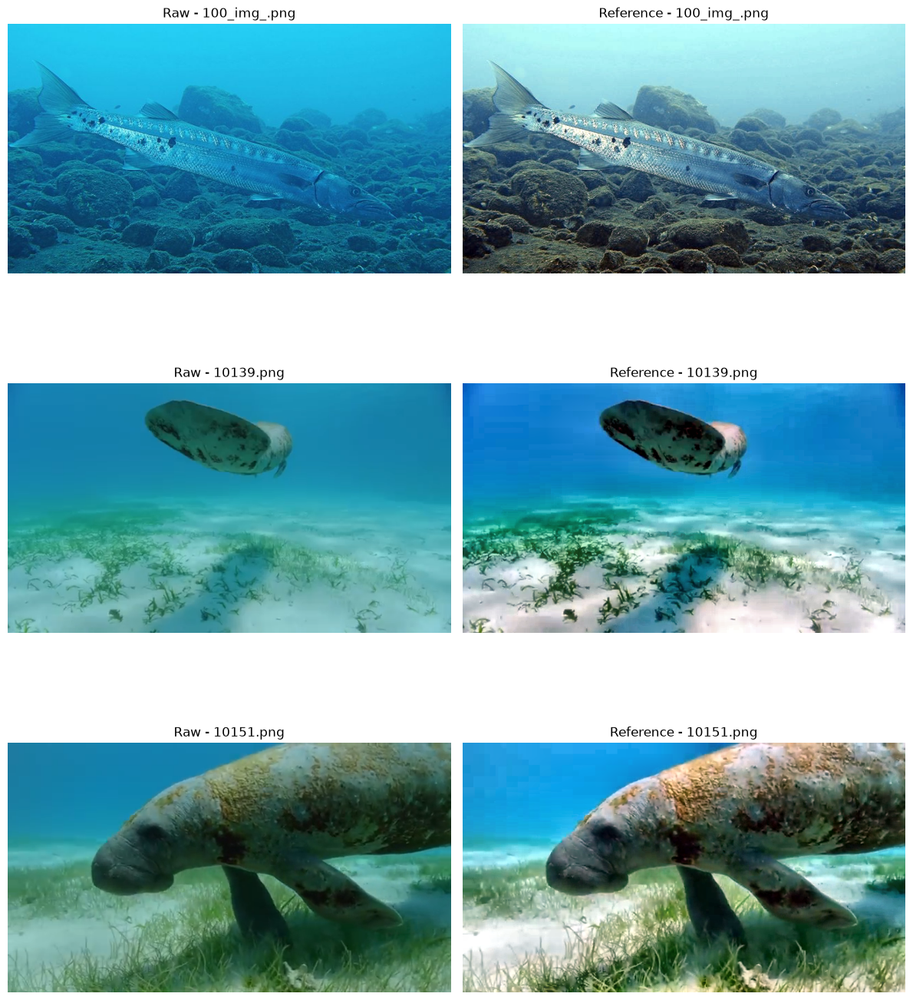

In [16]:
# Visual inspection of Raw and Reference image pairs

import cv2
import matplotlib.pyplot as plt
import random

sample_names = sorted(raw_files)[:3]

fig, axes = plt.subplots(3, 2, figsize=(12, 15))

for i, name in enumerate(sample_names):
    raw_img = cv2.imread(str(RAW_DIR / name))
    ref_img = cv2.imread(str(REF_DIR / name))

    raw_img = cv2.cvtColor(raw_img, cv2.COLOR_BGR2RGB)
    ref_img = cv2.cvtColor(ref_img, cv2.COLOR_BGR2RGB)

    axes[i, 0].imshow(raw_img)
    axes[i, 0].set_title(f"Raw - {name}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(ref_img)
    axes[i, 1].set_title(f"Reference - {name}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

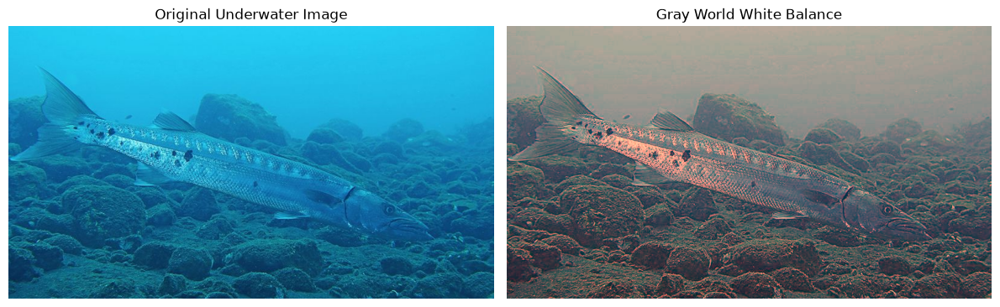

In [17]:
# AquaLume Baseline 1: Gray World White Balance

import numpy as np
import cv2
import matplotlib.pyplot as plt

def gray_world_white_balance(image):
    """
    Gray World White Balance
    Input: RGB image
    Output: Enhanced RGB image
    """
    img = image.astype(np.float32)

    channel_means = np.mean(img, axis=(0, 1))
    gray_mean = np.mean(channel_means)

    scales = gray_mean / (channel_means + 1e-6)

    result = img * scales
    result = np.clip(result, 0, 255).astype(np.uint8)

    return result


# Test on one underwater image
sample_name = sorted(raw_files)[0]

image_bgr = cv2.imread(str(RAW_DIR / sample_name))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

enhanced_image = gray_world_white_balance(image_rgb)

# Display comparison
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Underwater Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(enhanced_image)
plt.title("Gray World White Balance")
plt.axis("off")

plt.tight_layout()
plt.show()

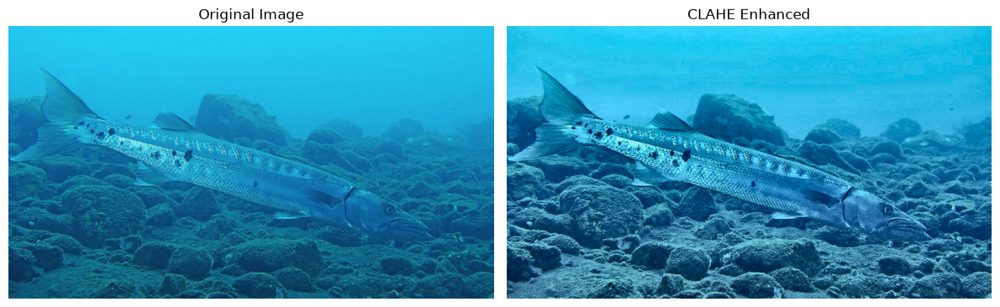

In [18]:
# AquaLume Baseline 2: CLAHE

def apply_clahe_rgb(image):
    """
    Apply CLAHE to the luminance channel in LAB color space.
    Input: RGB image
    Output: Enhanced RGB image
    """
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)

    l_channel, a_channel, b_channel = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced_l = clahe.apply(l_channel)

    enhanced_lab = cv2.merge((enhanced_l, a_channel, b_channel))

    result = cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2RGB)

    return result


clahe_result = apply_clahe_rgb(image_rgb)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(clahe_result)
plt.title("CLAHE Enhanced")
plt.axis("off")

plt.tight_layout()
plt.show()

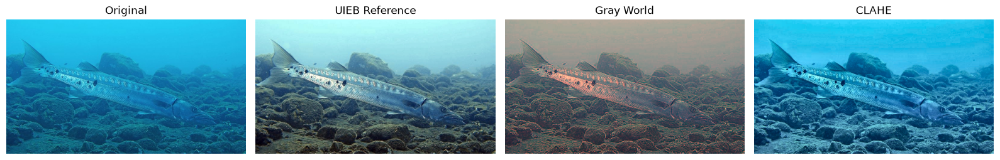

In [19]:
# AquaLume: Four-way visual comparison

plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)
plt.imshow(image_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 4, 2)
reference_bgr = cv2.imread(str(REF_DIR / sample_name))
reference_rgb = cv2.cvtColor(reference_bgr, cv2.COLOR_BGR2RGB)
plt.imshow(reference_rgb)
plt.title("UIEB Reference")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(enhanced_image)
plt.title("Gray World")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(clahe_result)
plt.title("CLAHE")
plt.axis("off")

plt.tight_layout()
plt.show()

In [20]:
# Save AquaLume Day 1 baseline experiment

from pathlib import Path
import cv2

OUTPUT_DIR = PROJECT_DIR / "outputs" / "day1_baselines"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save individual outputs
cv2.imwrite(
    str(OUTPUT_DIR / "original.png"),
    cv2.cvtColor(image_rgb, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(OUTPUT_DIR / "gray_world.png"),
    cv2.cvtColor(enhanced_image, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(OUTPUT_DIR / "clahe.png"),
    cv2.cvtColor(clahe_result, cv2.COLOR_RGB2BGR)
)

cv2.imwrite(
    str(OUTPUT_DIR / "reference.png"),
    reference_bgr
)

print("Baseline images saved successfully!")
print("Output directory:", OUTPUT_DIR)

Baseline images saved successfully!
Output directory: C:\Users\sarya\OneDrive\Documents\Underwater-Enhancement\outputs\day1_baselines


In [21]:
## Day 1 — Dataset Validation and Baseline Experiments

### Dataset Validation
The UIEB dataset was inspected and validated. A total of 890 raw underwater images and 890 corresponding reference images were found. Filename verification confirmed that all 890 image pairs matched, with no missing pairs. Additionally, 60 challenging underwater images were available for qualitative evaluation.

### Baseline Experiments

**1. Gray World White Balance**

The Gray World white balance algorithm was implemented to compensate for underwater color casts. In the inspected sample, the method introduced an excessive warm/reddish tone, suggesting that global channel balancing may not be suitable for all underwater scenes.

**2. CLAHE (Contrast Limited Adaptive Histogram Equalization)**

CLAHE was applied to the luminance channel in LAB color space. The inspected output showed improved local contrast and visibility of underwater objects and scene structures. However, the blue color cast remained.

### Initial Observation
CLAHE showed more promising visual results than Gray World White Balance for the inspected sample. These methods will serve as conventional baselines for comparison with the proposed AquaLume framework.

### Status
- Dataset validation: Completed
- Image pair verification: Completed
- Gray World baseline: Implemented
- CLAHE baseline: Implemented
- Initial visual comparison: Completed
- Baseline outputs: Saved

SyntaxError: invalid syntax (1777113767.py, line 4)

In [27]:
import numpy as np

def calculate_color_imbalance(image):
    """
    Calculates RGB channel means and a normalized color imbalance score.

    Input:
        image: RGB image as a NumPy array

    Output:
        Dictionary containing channel means, dominant channel,
        and color imbalance score.
    """

    image = image.astype(np.float32)

    # Calculate mean intensity of each RGB channel
    channel_means = np.mean(image, axis=(0, 1))

    red_mean, green_mean, blue_mean = channel_means

    # Calculate average intensity across all channels
    mean_intensity = np.mean(channel_means)

    # Avoid division by zero
    epsilon = 1e-6

    # Calculate normalized channel deviations
    deviations = np.abs(channel_means - mean_intensity) / (mean_intensity + epsilon)

    # Calculate overall color imbalance score
    imbalance_score = np.mean(deviations)

    # Identify dominant channel
    channel_names = ["Red", "Green", "Blue"]
    dominant_channel = channel_names[np.argmax(channel_means)]

    return {
        "red_mean": float(red_mean),
        "green_mean": float(green_mean),
        "blue_mean": float(blue_mean),
        "dominant_channel": dominant_channel,
        "color_imbalance_score": float(imbalance_score)
    }

In [22]:
from pathlib import Path
import os
import cv2
import numpy as np

PROJECT_DIR = Path.cwd()
DATASET_DIR = PROJECT_DIR / "datasets"
UIEB_DIR = DATASET_DIR / "UIEB"

RAW_DIR = UIEB_DIR / "Raw"
REF_DIR = UIEB_DIR / "References"
CHALLENGING_DIR = UIEB_DIR / "Challenging_Set"

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

raw_files = sorted([
    f.name for f in RAW_DIR.iterdir()
    if f.suffix.lower() in image_extensions
])

ref_files = sorted([
    f.name for f in REF_DIR.iterdir()
    if f.suffix.lower() in image_extensions
])

challenging_files = sorted([
    f.name for f in CHALLENGING_DIR.iterdir()
    if f.suffix.lower() in image_extensions
])

print("Raw images:", len(raw_files))
print("Reference images:", len(ref_files))
print("Challenging images:", len(challenging_files))

Raw images: 890
Reference images: 890
Challenging images: 60


In [28]:
sample_name = sorted(raw_files)[0]

image_bgr = cv2.imread(str(RAW_DIR / sample_name))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

color_analysis = calculate_color_imbalance(image_rgb)

print("Image:", sample_name)
print("Red Mean:", color_analysis["red_mean"])
print("Green Mean:", color_analysis["green_mean"])
print("Blue Mean:", color_analysis["blue_mean"])
print("Dominant Channel:", color_analysis["dominant_channel"])
print("Color Imbalance Score:", color_analysis["color_imbalance_score"])

Image: 100_img_.png
Red Mean: 22.8992919921875
Green Mean: 134.8262176513672
Blue Mean: 175.3550262451172
Dominant Channel: Blue
Color Imbalance Score: 0.5291666388511658


In [24]:
def calculate_contrast(image):
    """
    Calculates global grayscale contrast using intensity standard deviation.

    Input:
        image: RGB image as a NumPy array

    Output:
        Global grayscale intensity standard deviation.
    """

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    contrast_score = np.std(gray.astype(np.float32))

    return float(contrast_score)

In [25]:
contrast_score = calculate_contrast(image_rgb)

print("Image:", sample_name)
print("Global Contrast Score:", contrast_score)

Image: 100_img_.png
Global Contrast Score: 36.23588943481445


In [29]:
def calculate_visibility_proxy(image):
    """
    Estimates image sharpness using variance of the Laplacian.

    Higher values may indicate stronger edge/detail variation.
    This is a proxy, not a direct physical visibility measurement.
    """

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    laplacian = cv2.Laplacian(gray, cv2.CV_64F)

    visibility_score = laplacian.var()

    return float(visibility_score)

In [30]:
visibility_score = calculate_visibility_proxy(image_rgb)

print("Image:", sample_name)
print("Visibility (Laplacian Variance) Score:", visibility_score)

Image: 100_img_.png
Visibility (Laplacian Variance) Score: 664.334502531821


In [31]:
def extract_degradation_features(image):
    color_info = calculate_color_imbalance(image)
    contrast_info = calculate_contrast(image)
    visibility_info = calculate_visibility_proxy(image)

    feature_vector = np.array([
        color_info["color_imbalance_score"],
        contrast_info,
        visibility_info
    ], dtype=np.float32)

    return feature_vector

In [32]:
degradation_vector = extract_degradation_features(image_rgb)

print("Image:", sample_name)
print("Degradation Feature Vector:", degradation_vector)
print("Vector Shape:", degradation_vector.shape)

Image: 100_img_.png
Degradation Feature Vector: [5.2916664e-01 3.6235889e+01 6.6433447e+02]
Vector Shape: (3,)


In [33]:
sample_batch = raw_files[:5]

batch_features = []

for filename in sample_batch:
    image_bgr = cv2.imread(str(RAW_DIR / filename))
    image_rgb_batch = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

    features = extract_degradation_features(image_rgb_batch)
    batch_features.append(features)

batch_features = np.array(batch_features)

print("Batch feature matrix:")
print(batch_features)

print("Matrix shape:", batch_features.shape)

Batch feature matrix:
[[5.2916664e-01 3.6235889e+01 6.6433447e+02]
 [3.6587223e-01 2.9125671e+01 5.5640713e+01]
 [2.2794531e-01 4.3918797e+01 9.4509010e+01]
 [1.7939188e-01 4.5621658e+01 6.8934967e+01]
 [4.1035423e-01 6.3308090e+01 1.1644039e+02]]
Matrix shape: (5, 3)


In [34]:
all_degradation_features = []

for i, filename in enumerate(raw_files):
    image_bgr = cv2.imread(str(RAW_DIR / filename))

    if image_bgr is None:
        print("Failed to load:", filename)
        continue

    image_rgb_batch = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

    features = extract_degradation_features(image_rgb_batch)
    all_degradation_features.append(features)

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(raw_files)} images")

all_degradation_features = np.array(all_degradation_features, dtype=np.float32)

print("\nExtraction complete!")
print("Feature matrix shape:", all_degradation_features.shape)

Processed 100/890 images
Processed 200/890 images
Processed 300/890 images
Processed 400/890 images
Processed 500/890 images
Processed 600/890 images
Processed 700/890 images
Processed 800/890 images

Extraction complete!
Feature matrix shape: (890, 3)


In [35]:
feature_names = [
    "Color Imbalance",
    "Global Contrast",
    "Laplacian Variance"
]

for i, name in enumerate(feature_names):
    values = all_degradation_features[:, i]

    print(f"\n{name}")
    print("-" * 30)
    print("Mean:", np.mean(values))
    print("Standard Deviation:", np.std(values))
    print("Minimum:", np.min(values))
    print("Maximum:", np.max(values))


Color Imbalance
------------------------------
Mean: 0.27684367
Standard Deviation: 0.18793656
Minimum: 0.001204179
Maximum: 0.9138383

Global Contrast
------------------------------
Mean: 36.317097
Standard Deviation: 13.070666
Minimum: 4.2682805
Maximum: 75.675735

Laplacian Variance
------------------------------
Mean: 561.168
Standard Deviation: 959.3753
Minimum: 2.2094896
Maximum: 11138.816


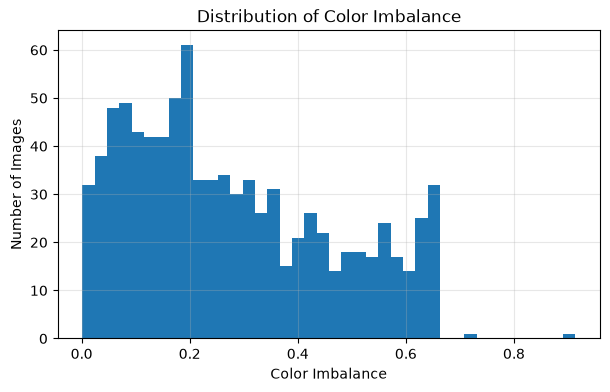

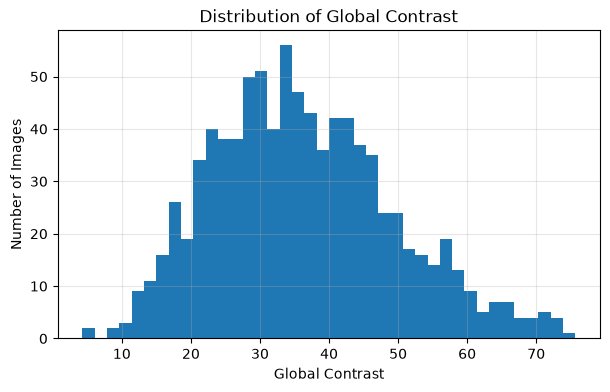

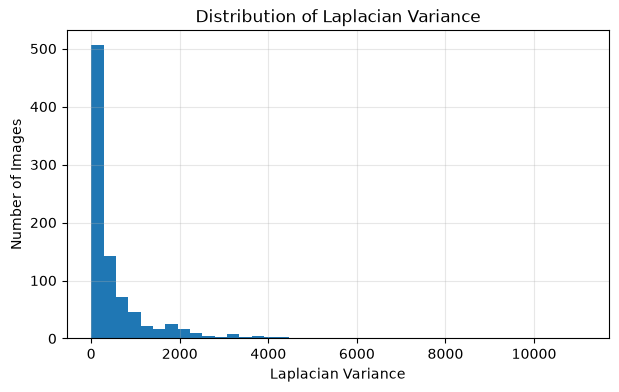

In [36]:
import matplotlib.pyplot as plt

for i, name in enumerate(feature_names):
    plt.figure(figsize=(7, 4))

    plt.hist(all_degradation_features[:, i], bins=40)

    plt.title(f"Distribution of {name}")
    plt.xlabel(name)
    plt.ylabel("Number of Images")
    plt.grid(alpha=0.3)

    plt.show()

In [37]:
from scipy.stats import skew

for i, name in enumerate(feature_names):
    values = all_degradation_features[:, i]

    print(f"\n{name}")
    print("-" * 30)
    print("Skewness:", skew(values))
    print("Median:", np.median(values))
    print("95th percentile:", np.percentile(values, 95))
    print("99th percentile:", np.percentile(values, 99))


Color Imbalance
------------------------------
Skewness: 0.5433352
Median: 0.23271018
95th percentile: 0.6335154
99th percentile: 0.6558625

Global Contrast
------------------------------
Skewness: 0.4241444
Median: 35.023468
95th percentile: 59.794792
99th percentile: 70.35799

Laplacian Variance
------------------------------
Skewness: 4.47173
Median: 206.36557
95th percentile: 2230.3147
99th percentile: 4175.3584


In [38]:
# Copy our original degradation feature matrix
transformed_features = all_degradation_features.copy()

# Apply logarithmic transformation to Laplacian Variance
transformed_features[:, 2] = np.log1p(
    transformed_features[:, 2]
)

print("Original Laplacian Variance:")
print("Mean:", np.mean(all_degradation_features[:, 2]))
print("Median:", np.median(all_degradation_features[:, 2]))

print("\nTransformed Laplacian Variance:")
print("Mean:", np.mean(transformed_features[:, 2]))
print("Median:", np.median(transformed_features[:, 2]))

print("\nTransformed feature matrix shape:",
      transformed_features.shape)

Original Laplacian Variance:
Mean: 561.168
Median: 206.36557

Transformed Laplacian Variance:
Mean: 5.334077
Median: 5.3344803

Transformed feature matrix shape: (890, 3)


Original skewness: 4.47173
Transformed skewness: -0.086503476


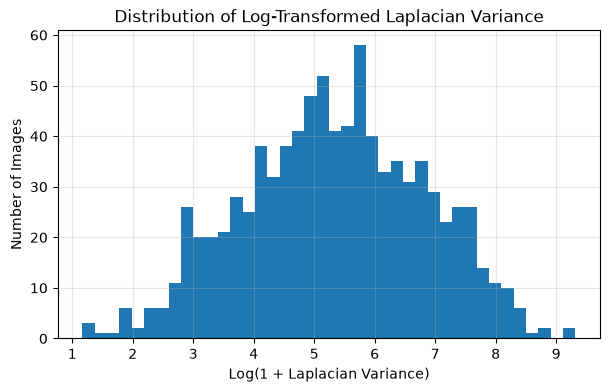

In [39]:
from scipy.stats import skew

original_laplacian = all_degradation_features[:, 2]
transformed_laplacian = transformed_features[:, 2]

print("Original skewness:", skew(original_laplacian))
print("Transformed skewness:", skew(transformed_laplacian))

plt.figure(figsize=(7, 4))
plt.hist(transformed_laplacian, bins=40)

plt.title("Distribution of Log-Transformed Laplacian Variance")
plt.xlabel("Log(1 + Laplacian Variance)")
plt.ylabel("Number of Images")
plt.grid(alpha=0.3)

plt.show()

In [40]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_features = scaler.fit_transform(transformed_features)

print("Scaled feature matrix shape:", scaled_features.shape)

print("\nFeature means:")
print(np.mean(scaled_features, axis=0))

print("\nFeature standard deviations:")
print(np.std(scaled_features, axis=0))

Scaled feature matrix shape: (890, 3)

Feature means:
[2.6922548e-08 1.3293845e-07 6.2166308e-08]

Feature standard deviations:
[0.99999976 1.0000002  0.9999998 ]


In [41]:
import sklearn

print("Scikit-learn:", sklearn.__version__)
print("Installed location:", sklearn.__file__)

Scikit-learn: 1.9.1
Installed location: C:\Users\sarya\anaconda3\envs\underwater\Lib\site-packages\sklearn\__init__.py


In [ ]:
import sys

print(sys.executable)

In [ ]:
import sys
!{sys.executable} -m pip install scikit-learn

In [ ]:
import sklearn

print("Version:", sklearn.__version__)
print("Location:", sklearn.__file__)

In [42]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled_features = scaler.fit_transform(transformed_features)

print("Scaled feature matrix shape:", scaled_features.shape)

print("\nFeature means:")
print(np.mean(scaled_features, axis=0))

print("\nFeature standard deviations:")
print(np.std(scaled_features, axis=0))

Scaled feature matrix shape: (890, 3)

Feature means:
[2.6922548e-08 1.3293845e-07 6.2166308e-08]

Feature standard deviations:
[0.99999976 1.0000002  0.9999998 ]


In [43]:
import pandas as pd

# Create output directory
DEGRADATION_DIR = PROJECT_DIR / "outputs" / "day2_degradation_analysis"
DEGRADATION_DIR.mkdir(parents=True, exist_ok=True)

# Create feature table
feature_df = pd.DataFrame({
    "filename": raw_files,
    "color_imbalance": all_degradation_features[:, 0],
    "global_contrast": all_degradation_features[:, 1],
    "laplacian_variance": all_degradation_features[:, 2],
    "log_laplacian_variance": transformed_features[:, 2],
    "scaled_color_imbalance": scaled_features[:, 0],
    "scaled_global_contrast": scaled_features[:, 1],
    "scaled_log_laplacian": scaled_features[:, 2]
})

# Save CSV
feature_csv_path = DEGRADATION_DIR / "degradation_features.csv"
feature_df.to_csv(feature_csv_path, index=False)

print("Saved:", feature_csv_path)
print("\nDataset shape:", feature_df.shape)
print("\nFirst five rows:")
display(feature_df.head())

Saved: C:\Users\sarya\OneDrive\Documents\Underwater-Enhancement\outputs\day2_degradation_analysis\degradation_features.csv

Dataset shape: (890, 8)

First five rows:


,filename,color_imbalance,global_contrast,laplacian_variance,log_laplacian_variance,scaled_color_imbalance,scaled_global_contrast,scaled_log_laplacian
0,100_img_.png,0.529167,36.235889,664.334473,6.500290,1.342597,-0.006213,0.779276
1,10139.png,0.365872,29.125671,55.640713,4.036728,0.473716,-0.550196,-0.866902
2,10151.png,0.227945,43.918797,94.509010,4.559221,-0.260185,0.581585,-0.517767
3,101_img_.png,0.179392,45.621658,68.934967,4.247566,-0.518536,0.711866,-0.726018
4,102_img_.png,0.410354,63.308090,116.440392,4.765931,0.710402,2.065006,-0.379641


In [44]:
from sklearn.model_selection import train_test_split

# First split: 70% train, 30% remaining
train_files, remaining_files = train_test_split(
    raw_files,
    test_size=0.30,
    random_state=42
)

# Second split: divide remaining 30% equally
val_files, test_files = train_test_split(
    remaining_files,
    test_size=0.50,
    random_state=42
)

print("Training images:", len(train_files))
print("Validation images:", len(val_files))
print("Testing images:", len(test_files))

print("\nTotal:", len(train_files) + len(val_files) + len(test_files))

Training images: 623
Validation images: 133
Testing images: 134

Total: 890


In [45]:
# Convert each split to a set
train_set = set(train_files)
val_set = set(val_files)
test_set = set(test_files)

# Check for overlap
print("Train-Val overlap:", len(train_set & val_set))
print("Train-Test overlap:", len(train_set & test_set))
print("Val-Test overlap:", len(val_set & test_set))

# Check total unique images
all_split_files = train_set | val_set | test_set

print("\nUnique images across splits:", len(all_split_files))

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0

Unique images across splits: 890


In [46]:
# Build split labels
split_mapping = {}

for filename in train_files:
    split_mapping[filename] = "train"

for filename in val_files:
    split_mapping[filename] = "validation"

for filename in test_files:
    split_mapping[filename] = "test"


# Build paired dataset manifest
manifest_df = feature_df.copy()

manifest_df["split"] = manifest_df["filename"].map(split_mapping)

manifest_df["raw_path"] = manifest_df["filename"].apply(
    lambda filename: str(RAW_DIR / filename)
)

manifest_df["reference_path"] = manifest_df["filename"].apply(
    lambda filename: str(REF_DIR / filename)
)


# Verify paths
manifest_df["raw_exists"] = manifest_df["raw_path"].apply(
    lambda path: Path(path).exists()
)

manifest_df["reference_exists"] = manifest_df["reference_path"].apply(
    lambda path: Path(path).exists()
)


# Save manifest
manifest_path = DEGRADATION_DIR / "dataset_manifest.csv"

manifest_df.to_csv(manifest_path, index=False)


print("Manifest shape:", manifest_df.shape)

print("\nSplit distribution:")
print(manifest_df["split"].value_counts())

print("\nMissing raw images:", (~manifest_df["raw_exists"]).sum())
print("Missing reference images:", (~manifest_df["reference_exists"]).sum())

print("\nSaved manifest:", manifest_path)

display(manifest_df.head())

Manifest shape: (890, 13)

Split distribution:
split
train         623
test          134
validation    133
Name: count, dtype: int64

Missing raw images: 0
Missing reference images: 0

Saved manifest: C:\Users\sarya\OneDrive\Documents\Underwater-Enhancement\outputs\day2_degradation_analysis\dataset_manifest.csv


,filename,color_imbalance,global_contrast,laplacian_variance,log_laplacian_variance,scaled_color_imbalance,scaled_global_contrast,scaled_log_laplacian,split,raw_path,reference_path,raw_exists,reference_exists
0,100_img_.png,0.529167,36.235889,664.334473,6.500290,1.342597,-0.006213,0.779276,train,C:\Users\sarya\OneDrive\Documents\Underwater-E...,C:\Users\sarya\OneDrive\Documents\Underwater-E...,True,True
1,10139.png,0.365872,29.125671,55.640713,4.036728,0.473716,-0.550196,-0.866902,train,C:\Users\sarya\OneDrive\Documents\Underwater-E...,C:\Users\sarya\OneDrive\Documents\Underwater-E...,True,True
2,10151.png,0.227945,43.918797,94.509010,4.559221,-0.260185,0.581585,-0.517767,validation,C:\Users\sarya\OneDrive\Documents\Underwater-E...,C:\Users\sarya\OneDrive\Documents\Underwater-E...,True,True
3,101_img_.png,0.179392,45.621658,68.934967,4.247566,-0.518536,0.711866,-0.726018,train,C:\Users\sarya\OneDrive\Documents\Underwater-E...,C:\Users\sarya\OneDrive\Documents\Underwater-E...,True,True
4,102_img_.png,0.410354,63.308090,116.440392,4.765931,0.710402,2.065006,-0.379641,train,C:\Users\sarya\OneDrive\Documents\Underwater-E...,C:\Users\sarya\OneDrive\Documents\Underwater-E...,True,True


In [47]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Get training rows only
train_manifest = manifest_df[manifest_df["split"] == "train"].copy()

# Extract the three features
train_degradation_raw = train_manifest[
    ["color_imbalance", "global_contrast", "laplacian_variance"]
].values.astype(np.float32)

# Log-transform Laplacian variance
train_degradation_raw[:, 2] = np.log1p(
    train_degradation_raw[:, 2]
)

# Fit scaler ONLY on training data
train_scaler = StandardScaler()

train_degradation_scaled = train_scaler.fit_transform(
    train_degradation_raw
)

print("Training feature matrix:", train_degradation_scaled.shape)

print("\nTraining means:")
print(train_degradation_scaled.mean(axis=0))

print("\nTraining standard deviations:")
print(train_degradation_scaled.std(axis=0))

Training feature matrix: (623, 3)

Training means:
[-2.1430884e-08 -7.9600426e-08  1.4695463e-07]

Training standard deviations:
[1.         0.99999994 1.        ]


In [48]:
# Extract validation features
val_manifest = manifest_df[manifest_df["split"] == "validation"].copy()

val_degradation_raw = val_manifest[
    ["color_imbalance", "global_contrast", "laplacian_variance"]
].values.astype(np.float32)

val_degradation_raw[:, 2] = np.log1p(val_degradation_raw[:, 2])

val_degradation_scaled = train_scaler.transform(val_degradation_raw)


# Extract test features
test_manifest = manifest_df[manifest_df["split"] == "test"].copy()

test_degradation_raw = test_manifest[
    ["color_imbalance", "global_contrast", "laplacian_variance"]
].values.astype(np.float32)

test_degradation_raw[:, 2] = np.log1p(test_degradation_raw[:, 2])

test_degradation_scaled = train_scaler.transform(test_degradation_raw)


# Verify
print("Train:", train_degradation_scaled.shape)
print("Validation:", val_degradation_scaled.shape)
print("Test:", test_degradation_scaled.shape)

Train: (623, 3)
Validation: (133, 3)
Test: (134, 3)


In [49]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

PyTorch version: 2.15.0+cpu
CUDA available: False
Device: CPU


In [ ]:
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cpu

In [50]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

PyTorch version: 2.15.0+cpu
CUDA available: False
Device: CPU


In [51]:
from torch.utils.data import Dataset
from PIL import Image
import torch
import numpy as np

IMAGE_SIZE = 256

class AquaLumeDataset(Dataset):

    def __init__(self, filenames, manifest, raw_dir, ref_dir, scaler):
        self.filenames = list(filenames)
        self.manifest = manifest
        self.raw_dir = raw_dir
        self.ref_dir = ref_dir
        self.scaler = scaler

        self.feature_columns = [
            "color_imbalance",
            "global_contrast",
            "laplacian_variance"
        ]

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, index):

        filename = self.filenames[index]

        # Load paired images
        raw_image = Image.open(
            self.raw_dir / filename
        ).convert("RGB")

        reference_image = Image.open(
            self.ref_dir / filename
        ).convert("RGB")

        # Resize
        raw_image = raw_image.resize(
            (IMAGE_SIZE, IMAGE_SIZE)
        )

        reference_image = reference_image.resize(
            (IMAGE_SIZE, IMAGE_SIZE)
        )

        # Convert to NumPy
        raw_array = np.asarray(raw_image, dtype=np.float32) / 255.0
        reference_array = np.asarray(reference_image, dtype=np.float32) / 255.0

        # HWC -> CHW
        raw_array = np.transpose(raw_array, (2, 0, 1))
        reference_array = np.transpose(reference_array, (2, 0, 1))

        # Image tensors
        raw_tensor = torch.tensor(raw_array, dtype=torch.float32)
        reference_tensor = torch.tensor(reference_array, dtype=torch.float32)

        # Retrieve degradation features for this image
        row = self.manifest[
            self.manifest["filename"] == filename
        ].iloc[0]

        degradation_features = row[
            self.feature_columns
        ].values.astype(np.float32)

        # Log-transform Laplacian variance
        degradation_features[2] = np.log1p(
            degradation_features[2]
        )

        # Apply training-fitted scaler
        degradation_features = self.scaler.transform(
            degradation_features.reshape(1, -1)
        )[0]

        degradation_tensor = torch.tensor(
            degradation_features,
            dtype=torch.float32
        )

        return {
            "input": raw_tensor,
            "target": reference_tensor,
            "degradation": degradation_tensor,
            "filename": filename
        }

In [52]:
# Create a dataset containing the training samples
train_dataset = AquaLumeDataset(
    filenames=train_files,
    manifest=manifest_df,
    raw_dir=RAW_DIR,
    ref_dir=REF_DIR,
    scaler=train_scaler
)

# Retrieve one sample
sample = train_dataset[0]

print("Input shape:", sample["input"].shape)
print("Target shape:", sample["target"].shape)
print("Degradation shape:", sample["degradation"].shape)
print("Filename:", sample["filename"])

print("\nInput range:", sample["input"].min().item(), sample["input"].max().item())
print("Target range:", sample["target"].min().item(), sample["target"].max().item())
print("Degradation features:", sample["degradation"])

Input shape: torch.Size([3, 256, 256])
Target shape: torch.Size([3, 256, 256])
Degradation shape: torch.Size([3])
Filename: 556_img_.png

Input range: 0.0 1.0
Target range: 0.0 1.0
Degradation features: tensor([ 0.6884,  0.5561, -0.1736])


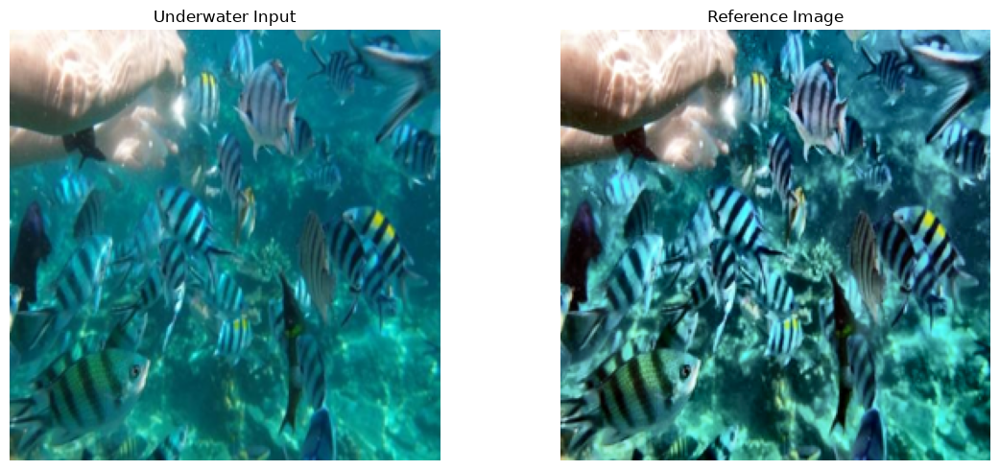

In [53]:
import matplotlib.pyplot as plt

input_image = sample["input"].permute(1, 2, 0).numpy()
target_image = sample["target"].permute(1, 2, 0).numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(input_image)
axes[0].set_title("Underwater Input")
axes[0].axis("off")

axes[1].imshow(target_image)
axes[1].set_title("Reference Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [54]:
from torch.utils.data import DataLoader

# Create datasets
train_dataset = AquaLumeDataset(
    filenames=train_files,
    manifest=manifest_df,
    raw_dir=RAW_DIR,
    ref_dir=REF_DIR,
    scaler=train_scaler
)

val_dataset = AquaLumeDataset(
    filenames=val_files,
    manifest=manifest_df,
    raw_dir=RAW_DIR,
    ref_dir=REF_DIR,
    scaler=train_scaler
)

test_dataset = AquaLumeDataset(
    filenames=test_files,
    manifest=manifest_df,
    raw_dir=RAW_DIR,
    ref_dir=REF_DIR,
    scaler=train_scaler
)


# Batch configuration
BATCH_SIZE = 8


# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)


print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 78
Validation batches: 17
Test batches: 17


In [55]:
batch = next(iter(train_loader))

print("Input batch:", batch["input"].shape)
print("Target batch:", batch["target"].shape)
print("Degradation batch:", batch["degradation"].shape)
print("Filenames in batch:", len(batch["filename"]))

print("\nBatch input range:",
      batch["input"].min().item(),
      batch["input"].max().item())

print("\nBatch target range:",
      batch["target"].min().item(),
      batch["target"].max().item())

Input batch: torch.Size([8, 3, 256, 256])
Target batch: torch.Size([8, 3, 256, 256])
Degradation batch: torch.Size([8, 3])
Filenames in batch: 8

Batch input range: 0.0 1.0

Batch target range: 0.0 1.0


In [56]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Device configuration
DEVICE = torch.device("cpu")

# Model configuration
MODEL_CONFIG = {
    "input_channels": 3,
    "image_size": 256,
    "cnn_features": 64,
    "transformer_dim": 64,
    "degradation_dim": 3,
    "batch_size": 8
}

print("Device:", DEVICE)
print("Model configuration:")
for key, value in MODEL_CONFIG.items():
    print(f"{key}: {value}")

Device: cpu
Model configuration:
input_channels: 3
image_size: 256
cnn_features: 64
transformer_dim: 64
degradation_dim: 3
batch_size: 8


In [57]:
class AquaLumeCNN(nn.Module):

    def __init__(self, input_channels=3, features=64):

        super().__init__()

        # Stage 1
        self.stage1 = nn.Sequential(
            nn.Conv2d(input_channels, features, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(features, features, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

        # Stage 2
        self.stage2 = nn.Sequential(
            nn.Conv2d(features, features, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(features, features, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

        # Stage 3
        self.stage3 = nn.Sequential(
            nn.Conv2d(features, features, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(features, features, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)

        return x

In [58]:
# Initialize the CNN
cnn_branch = AquaLumeCNN(
    input_channels=MODEL_CONFIG["input_channels"],
    features=MODEL_CONFIG["cnn_features"]
).to(DEVICE)

# Get a batch
batch = next(iter(train_loader))
input_images = batch["input"].to(DEVICE)

# Forward pass
with torch.no_grad():
    cnn_features = cnn_branch(input_images)

print("Input shape:", input_images.shape)
print("CNN output shape:", cnn_features.shape)
print("CNN output range:", cnn_features.min().item(), cnn_features.max().item())

Input shape: torch.Size([8, 3, 256, 256])
CNN output shape: torch.Size([8, 64, 256, 256])
CNN output range: 0.0 0.058746546506881714


In [59]:
class AquaLumeViT(nn.Module):

    def __init__(
        self,
        input_channels=3,
        embed_dim=64,
        patch_size=16,
        num_layers=2,
        num_heads=4
    ):

        super().__init__()

        # Convert image patches into token embeddings
        self.patch_embedding = nn.Conv2d(
            input_channels,
            embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        # Positional embeddings
        num_patches = (256 // patch_size) ** 2

        self.pos_embedding = nn.Parameter(
            torch.randn(1, num_patches, embed_dim) * 0.02
        )

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=128,
            dropout=0.1,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

    def forward(self, x):

        # Patch embedding
        x = self.patch_embedding(x)

        # B, C, H, W -> B, H, W, C
        x = x.permute(0, 2, 3, 1)

        # Convert spatial grid to sequence
        x = x.reshape(x.shape[0], -1, x.shape[-1])

        # Add positional embeddings
        x = x + self.pos_embedding

        # Global contextual processing
        x = self.transformer(x)

        return x

In [60]:
# Initialize ViT branch
vit_branch = AquaLumeViT(
    input_channels=MODEL_CONFIG["input_channels"],
    embed_dim=MODEL_CONFIG["transformer_dim"],
    patch_size=16,
    num_layers=2,
    num_heads=4
).to(DEVICE)

# Use the same batch
input_images = batch["input"].to(DEVICE)

# Forward pass
with torch.no_grad():
    vit_features = vit_branch(input_images)

print("Input shape:", input_images.shape)
print("ViT output shape:", vit_features.shape)
print("ViT output range:", vit_features.min().item(), vit_features.max().item())

Input shape: torch.Size([8, 3, 256, 256])
ViT output shape: torch.Size([8, 256, 64])
ViT output range: -3.4176180362701416 3.170503616333008


In [61]:
# Convert ViT tokens back into a spatial feature map

def vit_tokens_to_feature_map(tokens):

    batch_size, num_tokens, embed_dim = tokens.shape

    # 256 tokens -> 16 x 16 grid
    spatial_size = int(num_tokens ** 0.5)

    features = tokens.transpose(1, 2)

    features = features.reshape(
        batch_size,
        embed_dim,
        spatial_size,
        spatial_size
    )

    # Upsample to match CNN spatial dimensions
    features = F.interpolate(
        features,
        size=(256, 256),
        mode="bilinear",
        align_corners=False
    )

    return features


# Convert the current ViT output
vit_spatial_features = vit_tokens_to_feature_map(vit_features)

print("ViT token shape:", vit_features.shape)
print("ViT spatial shape:", vit_spatial_features.shape)
print("CNN feature shape:", cnn_features.shape)

ViT token shape: torch.Size([8, 256, 64])
ViT spatial shape: torch.Size([8, 64, 256, 256])
CNN feature shape: torch.Size([8, 64, 256, 256])


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [62]:
# Efficient spatial alignment for CNN and ViT features

# Reduce CNN feature resolution from 256x256 to 64x64
cnn_aligned_features = F.adaptive_avg_pool2d(
    cnn_features,
    output_size=(64, 64)
)

# Convert ViT tokens into their natural 16x16 spatial grid
batch_size, num_tokens, embed_dim = vit_features.shape

vit_grid_size = int(num_tokens ** 0.5)

vit_aligned_features = vit_features.transpose(1, 2).reshape(
    batch_size,
    embed_dim,
    vit_grid_size,
    vit_grid_size
)

# Upsample ViT features from 16x16 to 64x64
vit_aligned_features = F.interpolate(
    vit_aligned_features,
    size=(64, 64),
    mode="bilinear",
    align_corners=False
)

# Verify feature alignment
print("CNN aligned shape:", cnn_aligned_features.shape)
print("ViT aligned shape:", vit_aligned_features.shape)

CNN aligned shape: torch.Size([8, 64, 64, 64])
ViT aligned shape: torch.Size([8, 64, 64, 64])


In [ ]:
# Recreate the CNN branch

cnn_model = AquaLumeCNN(
    input_channels=MODEL_CONFIG["input_channels"],
    features=MODEL_CONFIG["cnn_features"]
).to(DEVICE)

print(cnn_model)

In [64]:
# AquaLume CNN branch

class AquaLumeCNN(nn.Module):
    def __init__(self, input_channels=3, features=64):
        super().__init__()

        self.stage1 = nn.Sequential(
            nn.Conv2d(input_channels, features, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(features, features, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.stage2 = nn.Sequential(
            nn.Conv2d(features, features, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(features, features, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.stage3 = nn.Sequential(
            nn.Conv2d(features, features, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(features, features, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        return x

In [ ]:
# Initialize the CNN model

cnn_model = AquaLumeCNN(
    input_channels=3,
    features=64
).to(DEVICE)

print("CNN model initialized successfully.")

In [ ]:
import torch

DEVICE = torch.device("cpu")

print("Device:", DEVICE)

In [ ]:
cnn_model = AquaLumeCNN(
    input_channels=3,
    features=64
).to(DEVICE)

print("CNN model initialized successfully.")

In [ ]:
# Retrieve one batch from the training DataLoader

batch = next(iter(train_loader))

input_batch = batch["input"].to(DEVICE)

print("Input batch shape:", input_batch.shape)

In [65]:
# Efficient spatial alignment for CNN and ViT features

# Reduce CNN feature resolution from 256x256 to 64x64
cnn_aligned_features = F.adaptive_avg_pool2d(
    cnn_features,
    output_size=(64, 64)
)

# Convert ViT tokens into their natural 16x16 spatial grid
batch_size, num_tokens, embed_dim = vit_features.shape

vit_grid_size = int(num_tokens ** 0.5)

vit_aligned_features = vit_features.transpose(1, 2).reshape(
    batch_size,
    embed_dim,
    vit_grid_size,
    vit_grid_size
)

# Upsample ViT features from 16x16 to 64x64
vit_aligned_features = F.interpolate(
    vit_aligned_features,
    size=(64, 64),
    mode="bilinear",
    align_corners=False
)

# Verify feature alignment
print("CNN aligned shape:", cnn_aligned_features.shape)
print("ViT aligned shape:", vit_aligned_features.shape)

CNN aligned shape: torch.Size([8, 64, 64, 64])
ViT aligned shape: torch.Size([8, 64, 64, 64])


In [66]:
# Degradation-Aware Adaptive Fusion Module

class AquaLumeFusion(nn.Module):

    def __init__(self, feature_channels=64, degradation_dim=3):
        super().__init__()

        # Predict fusion weights from degradation features
        self.weight_predictor = nn.Sequential(
            nn.Linear(degradation_dim, 32),
            nn.ReLU(inplace=True),
            nn.Linear(32, 2),
            nn.Softmax(dim=1)
        )

        # Fuse CNN and ViT features
        self.fusion_conv = nn.Sequential(
            nn.Conv2d(feature_channels * 2, feature_channels, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(feature_channels, feature_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, cnn_features, vit_features, degradation_features):

        # Generate branch weights from degradation information
        weights = self.weight_predictor(degradation_features)

        cnn_weight = weights[:, 0].view(-1, 1, 1, 1)
        vit_weight = weights[:, 1].view(-1, 1, 1, 1)

        # Weighted branch representations
        weighted_cnn = cnn_features * cnn_weight
        weighted_vit = vit_features * vit_weight

        # Concatenate weighted features
        fused = torch.cat(
            [weighted_cnn, weighted_vit],
            dim=1
        )

        # Learn fusion representation
        fused_features = self.fusion_conv(fused)

        return fused_features, weights

In [67]:
# Initialize the fusion module

fusion_model = AquaLumeFusion(
    feature_channels=64,
    degradation_dim=3
).to(DEVICE)

# Get degradation features from the current batch
degradation_batch = batch["degradation"].to(DEVICE)

# Test the fusion forward pass
fused_features, fusion_weights = fusion_model(
    cnn_aligned_features,
    vit_aligned_features,
    degradation_batch
)

# Verify outputs
print("Fused feature shape:", fused_features.shape)
print("Fusion weights shape:", fusion_weights.shape)
print("Fusion weights (first sample):", fusion_weights[0].detach().numpy())
print("Weight sum:", fusion_weights[0].sum().item())

Fused feature shape: torch.Size([8, 64, 64, 64])
Fusion weights shape: torch.Size([8, 2])
Fusion weights (first sample): [0.37260038 0.6273996 ]
Weight sum: 1.0


In [68]:
# AquaLume Physics-Inspired Degradation Pathway

class AquaLumePhysics(nn.Module):

    def __init__(self, input_channels=3, feature_channels=64, degradation_dim=3):
        super().__init__()

        # Extract spatial information from the RGB image
        self.image_encoder = nn.Sequential(
            nn.Conv2d(input_channels, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

        # Encode global degradation indicators
        self.degradation_encoder = nn.Sequential(
            nn.Linear(degradation_dim, 32),
            nn.ReLU(inplace=True),
            nn.Linear(32, 32),
            nn.ReLU(inplace=True)
        )

        # Combine image and degradation representations
        self.fusion = nn.Sequential(
            nn.Conv2d(64, feature_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(feature_channels, feature_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, image, degradation_features):

        # Extract spatial image features
        image_features = self.image_encoder(image)

        # Encode degradation information
        degradation_embedding = self.degradation_encoder(
            degradation_features
        )

        # Expand degradation embedding spatially
        degradation_map = degradation_embedding.unsqueeze(-1).unsqueeze(-1)

        degradation_map = degradation_map.expand(
            -1, -1, image_features.shape[2], image_features.shape[3]
        )

        # Combine image and degradation features
        combined = torch.cat(
            [image_features, degradation_map],
            dim=1
        )

        physics_features = self.fusion(combined)

        return physics_features

In [70]:
# Retrieve a batch from the training DataLoader

batch = next(iter(train_loader))

input_batch = batch["input"].to(DEVICE)
degradation_batch = batch["degradation"].to(DEVICE)

print("Input batch shape:", input_batch.shape)
print("Degradation batch shape:", degradation_batch.shape)

Input batch shape: torch.Size([8, 3, 256, 256])
Degradation batch shape: torch.Size([8, 3])


In [71]:
# Initialize the physics-inspired pathway

physics_model = AquaLumePhysics(
    input_channels=3,
    feature_channels=64,
    degradation_dim=3
).to(DEVICE)

# Pass the image and degradation features through the pathway
physics_features = physics_model(
    input_batch,
    degradation_batch
)

# Verify output
print("Physics feature shape:", physics_features.shape)
print("Physics feature range:",
      physics_features.min().item(),
      physics_features.max().item())

Physics feature shape: torch.Size([8, 64, 256, 256])
Physics feature range: 0.0 0.18116866052150726


In [72]:
class AquaLumePhysics(nn.Module):
    def __init__(self, input_channels=3, feature_channels=64, degradation_dim=3):
        super().__init__()

        self.image_encoder = nn.Sequential(
            nn.Conv2d(input_channels, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

        self.degradation_encoder = nn.Sequential(
            nn.Linear(degradation_dim, 32),
            nn.ReLU(inplace=True),
            nn.Linear(32, 32),
            nn.ReLU(inplace=True)
        )

        self.fusion = nn.Sequential(
            nn.Conv2d(64, feature_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(feature_channels, feature_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, image, degradation_features):

        # Reduce spatial resolution to save memory
        image = F.interpolate(
            image, size=(64, 64),
            mode="bilinear", align_corners=False
        )

        image_features = self.image_encoder(image)

        degradation_embedding = self.degradation_encoder(
            degradation_features
        )

        degradation_map = degradation_embedding.unsqueeze(-1).unsqueeze(-1)

        degradation_map = degradation_map.expand(
            -1, -1, image_features.shape[2], image_features.shape[3]
        )

        combined = torch.cat(
            [image_features, degradation_map], dim=1
        )

        physics_features = self.fusion(combined)

        return physics_features

In [73]:
# Initialize the optimized physics pathway

physics_model = AquaLumePhysics(
    input_channels=3,
    feature_channels=64,
    degradation_dim=3
).to(DEVICE)

# Forward pass
physics_features = physics_model(
    input_batch,
    degradation_batch
)

# Verify output
print("Physics feature shape:", physics_features.shape)
print("Physics feature range:",
      physics_features.min().item(),
      physics_features.max().item())

Physics feature shape: torch.Size([8, 64, 64, 64])
Physics feature range: 0.0 0.179664745926857


In [74]:
class AquaLumeThreeBranchFusion(nn.Module):
    def __init__(self, feature_channels=64, degradation_dim=3):
        super().__init__()

        # Predict adaptive weights for 3 branches
        self.weight_predictor = nn.Sequential(
            nn.Linear(degradation_dim, 32),
            nn.ReLU(inplace=True),
            nn.Linear(32, 3),
            nn.Softmax(dim=1)
        )

        # Fuse the weighted feature maps
        self.fusion_conv = nn.Sequential(
            nn.Conv2d(feature_channels * 3, feature_channels, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(feature_channels, feature_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, cnn_features, vit_features, physics_features,
                degradation_features):

        weights = self.weight_predictor(degradation_features)

        cnn_weight = weights[:, 0].view(-1, 1, 1, 1)
        vit_weight = weights[:, 1].view(-1, 1, 1, 1)
        physics_weight = weights[:, 2].view(-1, 1, 1, 1)

        weighted_cnn = cnn_features * cnn_weight
        weighted_vit = vit_features * vit_weight
        weighted_physics = physics_features * physics_weight

        combined = torch.cat(
            [weighted_cnn, weighted_vit, weighted_physics],
            dim=1
        )

        fused_features = self.fusion_conv(combined)

        return fused_features, weights

In [75]:
# Initialize three-branch fusion

three_branch_fusion = AquaLumeThreeBranchFusion(
    feature_channels=64,
    degradation_dim=3
).to(DEVICE)

# Fuse all three feature branches
fused_three_branch_features, three_branch_weights = three_branch_fusion(
    cnn_aligned_features,
    vit_aligned_features,
    physics_features,
    degradation_batch
)

# Verify outputs
print("Fused feature shape:", fused_three_branch_features.shape)
print("Branch weights shape:", three_branch_weights.shape)

print("First sample branch weights:",
      three_branch_weights[0].detach().cpu().numpy())

print("Weight sum:",
      three_branch_weights[0].sum().item())

Fused feature shape: torch.Size([8, 64, 64, 64])
Branch weights shape: torch.Size([8, 3])
First sample branch weights: [0.17526303 0.3635273  0.46120968]
Weight sum: 1.0


In [76]:
class AquaLumeDecoder(nn.Module):
    def __init__(self, feature_channels=64, output_channels=3):
        super().__init__()

        self.decoder = nn.Sequential(
            nn.Conv2d(feature_channels, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),

            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            nn.Upsample(scale_factor=2, mode="bilinear", align_corners=False),

            nn.Conv2d(32, 16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(16, output_channels, kernel_size=3, padding=1),

            nn.Sigmoid()
        )

    def forward(self, fused_features):
        return self.decoder(fused_features)

In [77]:
# Initialize the decoder

decoder_model = AquaLumeDecoder(
    feature_channels=64,
    output_channels=3
).to(DEVICE)

# Reconstruct the enhanced image
enhanced_output = decoder_model(fused_three_branch_features)

# Verify output
print("Enhanced output shape:", enhanced_output.shape)
print("Output pixel range:",
      enhanced_output.min().item(),
      enhanced_output.max().item())

Enhanced output shape: torch.Size([8, 3, 256, 256])
Output pixel range: 0.48910507559776306 0.5097994804382324


In [78]:
class AquaLume(nn.Module):
    def __init__(self):
        super().__init__()

        self.cnn = AquaLumeCNN(
            input_channels=3,
            features=64
        )

        self.vit = AquaLumeViT(
            input_channels=3,
            embed_dim=64,
            patch_size=16,
            num_layers=2,
            num_heads=4
        )

        self.physics = AquaLumePhysics(
            input_channels=3,
            feature_channels=64,
            degradation_dim=3
        )

        self.fusion = AquaLumeThreeBranchFusion(
            feature_channels=64,
            degradation_dim=3
        )

        self.decoder = AquaLumeDecoder(
            feature_channels=64,
            output_channels=3
        )

    def forward(self, image, degradation_features):

        # 1. CNN local feature extraction
        cnn_features = self.cnn(image)

        # Reduce CNN spatial resolution to 64x64
        cnn_features = F.adaptive_avg_pool2d(
            cnn_features, (64, 64)
        )

        # 2. ViT global feature extraction
        vit_tokens = self.vit(image)

        batch_size, num_tokens, embed_dim = vit_tokens.shape

        grid_size = int(num_tokens ** 0.5)

        vit_features = vit_tokens.transpose(1, 2).reshape(
            batch_size, embed_dim, grid_size, grid_size
        )

        vit_features = F.interpolate(
            vit_features,
            size=(64, 64),
            mode="bilinear",
            align_corners=False
        )

        # 3. Physics-inspired feature extraction
        physics_features = self.physics(
            image, degradation_features
        )

        # 4. Adaptive three-branch fusion
        fused_features, branch_weights = self.fusion(
            cnn_features,
            vit_features,
            physics_features,
            degradation_features
        )

        # 5. Image reconstruction
        enhanced_image = self.decoder(fused_features)

        return enhanced_image, branch_weights

In [79]:
# Initialize the complete AquaLume model

aqualume_model = AquaLume().to(DEVICE)

print("AquaLume model initialized successfully.")

AquaLume model initialized successfully.


In [80]:
# Test the complete AquaLume pipeline

aqualume_model.eval()

with torch.no_grad():
    test_output, test_weights = aqualume_model(
        input_batch,
        degradation_batch
    )

print("Output image shape:", test_output.shape)
print("Output pixel range:",
      test_output.min().item(),
      test_output.max().item())

print("Branch weights shape:", test_weights.shape)
print("First sample weights:",
      test_weights[0].cpu().numpy())

print("First sample weight sum:",
      test_weights[0].sum().item())

Output image shape: torch.Size([8, 3, 256, 256])
Output pixel range: 0.4872106611728668 0.5190029144287109
Branch weights shape: torch.Size([8, 3])
First sample weights: [0.3545492  0.37860912 0.2668417 ]
First sample weight sum: 1.0


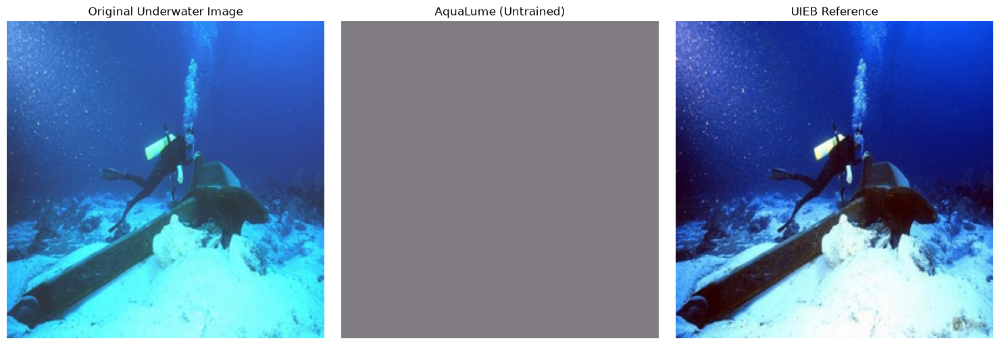

In [81]:
import matplotlib.pyplot as plt

# Select the first sample from the batch
input_image = input_batch[0].detach().cpu().permute(1, 2, 0).numpy()
reference_image = batch["target"][0].permute(1, 2, 0).numpy()
output_image = test_output[0].detach().cpu().permute(1, 2, 0).numpy()

# Display comparison
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(input_image)
plt.title("Original Underwater Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(output_image)
plt.title("AquaLume (Untrained)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(reference_image)
plt.title("UIEB Reference")
plt.axis("off")

plt.tight_layout()
plt.show()

In [82]:
# L1 Reconstruction Loss

l1_loss_function = nn.L1Loss()

l1_loss_value = l1_loss_function(
    test_output,
    batch["target"].to(DEVICE)
)

print("L1 Reconstruction Loss:", l1_loss_value.item())

L1 Reconstruction Loss: 0.23091818392276764


In [83]:
import importlib.util

print("pytorch_msssim installed:",
      importlib.util.find_spec("pytorch_msssim") is not None)

pytorch_msssim installed: False


In [84]:
import sys
!{sys.executable} -m pip install pytorch-msssim

In [85]:
from pytorch_msssim import ssim

print("pytorch-msssim imported successfully.")

pytorch-msssim imported successfully.


In [86]:
# Calculate Structural Similarity (SSIM)

ssim_value = ssim(
    test_output,
    batch["target"].to(DEVICE),
    data_range=1.0,
    size_average=True,
    nonnegative_ssim=True
)

ssim_loss_value = 1 - ssim_value

print("SSIM Score:", ssim_value.item())
print("SSIM Loss:", ssim_loss_value.item())

SSIM Score: 0.363776832818985
SSIM Loss: 0.6362231969833374


In [87]:
# Gradient Loss Implementation

def gradient_loss(prediction, target):
    # Horizontal gradients
    pred_dx = prediction[:, :, :, 1:] - prediction[:, :, :, :-1]
    target_dx = target[:, :, :, 1:] - target[:, :, :, :-1]

    # Vertical gradients
    pred_dy = prediction[:, :, 1:, :] - prediction[:, :, :-1, :]
    target_dy = target[:, :, 1:, :] - target[:, :, :-1, :]

    # Compare gradients
    loss_x = torch.mean(torch.abs(pred_dx - target_dx))
    loss_y = torch.mean(torch.abs(pred_dy - target_dy))

    return loss_x + loss_y


gradient_loss_value = gradient_loss(
    test_output,
    batch["target"].to(DEVICE)
)

print("Gradient Loss:", gradient_loss_value.item())

Gradient Loss: 0.06509532034397125


In [88]:
# AquaLume Combined Loss Function

def aqualume_loss(prediction, target):
    l1 = l1_loss_function(prediction, target)

    ssim_score = ssim(
        prediction,
        target,
        data_range=1.0,
        size_average=True,
        nonnegative_ssim=True
    )
    ssim_loss = 1 - ssim_score

    grad_loss = gradient_loss(prediction, target)

    total_loss = (
        1.0 * l1 +
        0.5 * ssim_loss +
        0.1 * grad_loss
    )

    return total_loss, l1, ssim_loss, grad_loss

In [89]:
# Test combined loss

total_loss_value, l1_value, ssim_loss_value, grad_loss_value = aqualume_loss(
    test_output,
    batch["target"].to(DEVICE)
)

print("Total Loss:", total_loss_value.item())
print("L1 Loss:", l1_value.item())
print("SSIM Loss:", ssim_loss_value.item())
print("Gradient Loss:", grad_loss_value.item())

Total Loss: 0.5555393099784851
L1 Loss: 0.23091818392276764
SSIM Loss: 0.6362231969833374
Gradient Loss: 0.06509532034397125


In [90]:
# Gradient flow verification

aqualume_model.train()

test_batch = next(iter(train_loader))

test_input = test_batch["input"].to(DEVICE)
test_target = test_batch["target"].to(DEVICE)
test_degradation = test_batch["degradation"].to(DEVICE)

aqualume_model.zero_grad()

test_prediction, test_weights = aqualume_model(
    test_input,
    test_degradation
)

test_total_loss, _, _, _ = aqualume_loss(
    test_prediction,
    test_target
)

test_total_loss.backward()

print("Backward propagation successful!")
print("Loss:", test_total_loss.item())

gradient_exists = any(
    parameter.grad is not None
    for parameter in aqualume_model.parameters()
    if parameter.requires_grad
)

print("Model gradients available:", gradient_exists)

Backward propagation successful!
Loss: 0.5226259231567383
Model gradients available: True


In [91]:
# AquaLume Training Configuration

import torch.optim as optim

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-5

optimizer = optim.Adam(
    aqualume_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("Optimizer:", optimizer.__class__.__name__)
print("Learning Rate:", LEARNING_RATE)
print("Weight Decay:", WEIGHT_DECAY)
print("Optimizer configured successfully.")

Optimizer: Adam
Learning Rate: 0.0001
Weight Decay: 1e-05
Optimizer configured successfully.


In [92]:
# AquaLume Training Configuration

import os

NUM_EPOCHS = 50
PATIENCE = 8
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-5

CHECKPOINT_DIR = "outputs/checkpoints"
LOG_DIR = "outputs/training_logs"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)

BEST_MODEL_PATH = os.path.join(
    CHECKPOINT_DIR,
    "aqualume_best_model.pth"
)

print("Training configuration initialized.")
print("Epochs:", NUM_EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Log directory:", LOG_DIR)
print("Best model path:", BEST_MODEL_PATH)

Training configuration initialized.
Epochs: 50
Early stopping patience: 8
Checkpoint directory: outputs/checkpoints
Log directory: outputs/training_logs
Best model path: outputs/checkpoints\aqualume_best_model.pth


In [93]:
# AquaLume Training History Tracker

training_history = {
    "train_total_loss": [],
    "train_l1_loss": [],
    "train_ssim_loss": [],
    "train_gradient_loss": [],
    "val_total_loss": [],
    "val_l1_loss": [],
    "val_ssim_loss": [],
    "val_gradient_loss": []
}

print("Training history tracker initialized.")
print("Metrics tracked:", list(training_history.keys()))

Training history tracker initialized.
Metrics tracked: ['train_total_loss', 'train_l1_loss', 'train_ssim_loss', 'train_gradient_loss', 'val_total_loss', 'val_l1_loss', 'val_ssim_loss', 'val_gradient_loss']


In [94]:
# AquaLume: Training One Epoch

def train_one_epoch(model, loader, optimizer, device):

    model.train()

    running_losses = {
        "total": 0.0,
        "l1": 0.0,
        "ssim": 0.0,
        "gradient": 0.0
    }

    num_batches = len(loader)

    for batch_data in loader:

        inputs = batch_data["input"].to(device)
        targets = batch_data["target"].to(device)
        degradation = batch_data["degradation"].to(device)

        optimizer.zero_grad(set_to_none=True)

        predictions, branch_weights = model(inputs, degradation)

        total_loss, l1, ssim_loss, grad_loss = aqualume_loss(
            predictions, targets
        )

        total_loss.backward()

        optimizer.step()

        running_losses["total"] += total_loss.item()
        running_losses["l1"] += l1.item()
        running_losses["ssim"] += ssim_loss.item()
        running_losses["gradient"] += grad_loss.item()

    epoch_losses = {
        key: value / num_batches
        for key, value in running_losses.items()
    }

    return epoch_losses

In [95]:
# AquaLume: Validation One Epoch

def validate_one_epoch(model, loader, device):

    model.eval()

    running_losses = {
        "total": 0.0,
        "l1": 0.0,
        "ssim": 0.0,
        "gradient": 0.0
    }

    num_batches = len(loader)

    with torch.no_grad():

        for batch_data in loader:

            inputs = batch_data["input"].to(device)
            targets = batch_data["target"].to(device)
            degradation = batch_data["degradation"].to(device)

            predictions, branch_weights = model(
                inputs, degradation
            )

            total_loss, l1, ssim_loss, grad_loss = aqualume_loss(
                predictions, targets
            )

            running_losses["total"] += total_loss.item()
            running_losses["l1"] += l1.item()
            running_losses["ssim"] += ssim_loss.item()
            running_losses["gradient"] += grad_loss.item()

    epoch_losses = {
        key: value / num_batches
        for key, value in running_losses.items()
    }

    return epoch_losses

In [96]:
# AquaLume Learning Rate Scheduler

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

print("Learning rate scheduler configured.")
print("Scheduler:", scheduler.__class__.__name__)
print("Reduction factor:", 0.5)
print("Scheduler patience:", 3)
print("Minimum learning rate:", 1e-6)

Learning rate scheduler configured.
Scheduler: ReduceLROnPlateau
Reduction factor: 0.5
Scheduler patience: 3
Minimum learning rate: 1e-06


In [97]:
# AquaLume Checkpoint Saving Function

def save_checkpoint(
    model,
    optimizer,
    scheduler,
    epoch,
    val_loss,
    filepath
):

    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "validation_loss": val_loss
    }

    torch.save(checkpoint, filepath)

    print(f"Checkpoint saved: {filepath}")

In [98]:
# AquaLume Early Stopping

class EarlyStopping:

    def __init__(self, patience=8, min_delta=0.0):

        self.patience = patience
        self.min_delta = min_delta
        self.best_loss = float("inf")
        self.counter = 0
        self.should_stop = False

    def __call__(self, val_loss):

        if val_loss < self.best_loss - self.min_delta:

            self.best_loss = val_loss
            self.counter = 0

        else:

            self.counter += 1

        if self.counter >= self.patience:

            self.should_stop = True

        return self.should_stop


early_stopping = EarlyStopping(
    patience=PATIENCE,
    min_delta=0.0
)

print("Early stopping mechanism initialized.")
print("Patience:", early_stopping.patience)

Early stopping mechanism initialized.
Patience: 8


In [99]:
# AquaLume: Complete Training Loop

def train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    scheduler,
    device,
    num_epochs,
    early_stopping,
    history,
    checkpoint_path
):

    best_val_loss = float("inf")

    for epoch in range(num_epochs):

        train_losses = train_one_epoch(
            model, train_loader, optimizer, device
        )

        val_losses = validate_one_epoch(
            model, val_loader, device
        )

        scheduler.step(val_losses["total"])

        # Record training history
        history["train_total_loss"].append(train_losses["total"])
        history["train_l1_loss"].append(train_losses["l1"])
        history["train_ssim_loss"].append(train_losses["ssim"])
        history["train_gradient_loss"].append(train_losses["gradient"])

        history["val_total_loss"].append(val_losses["total"])
        history["val_l1_loss"].append(val_losses["l1"])
        history["val_ssim_loss"].append(val_losses["ssim"])
        history["val_gradient_loss"].append(val_losses["gradient"])

        # Save best checkpoint
        if val_losses["total"] < best_val_loss:

            best_val_loss = val_losses["total"]

            save_checkpoint(
                model,
                optimizer,
                scheduler,
                epoch + 1,
                best_val_loss,
                checkpoint_path
            )

        # Early stopping
        stop = early_stopping(val_losses["total"])

        current_lr = optimizer.param_groups[0]["lr"]

        print(f"\nEpoch {epoch + 1}/{num_epochs}")
        print(f"Train Loss: {train_losses['total']:.4f}")
        print(f"Validation Loss: {val_losses['total']:.4f}")
        print(f"Train L1: {train_losses['l1']:.4f}")
        print(f"Validation L1: {val_losses['l1']:.4f}")
        print(f"Train SSIM Loss: {train_losses['ssim']:.4f}")
        print(f"Validation SSIM Loss: {val_losses['ssim']:.4f}")
        print(f"Train Gradient Loss: {train_losses['gradient']:.4f}")
        print(f"Validation Gradient Loss: {val_losses['gradient']:.4f}")
        print(f"Learning Rate: {current_lr:.6f}")

        if stop:

            print("\nEarly stopping triggered.")
            break

    print("\nTraining finished.")
    print("Best validation loss:", best_val_loss)

    return history

In [100]:
# AquaLume Model Complexity Analysis

total_parameters = sum(
    parameter.numel()
    for parameter in aqualume_model.parameters()
)

trainable_parameters = sum(
    parameter.numel()
    for parameter in aqualume_model.parameters()
    if parameter.requires_grad
)

non_trainable_parameters = total_parameters - trainable_parameters

print("AquaLume Model Complexity")
print("-" * 40)
print(f"Total parameters: {total_parameters:,}")
print(f"Trainable parameters: {trainable_parameters:,}")
print(f"Non-trainable parameters: {non_trainable_parameters:,}")
print(f"Parameter count (Millions): {total_parameters / 1e6:.4f} M")
print(f"FP32 parameter storage (MB): {total_parameters * 4 / (1024**2):.2f} MB")

AquaLume Model Complexity
----------------------------------------
Total parameters: 514,118
Trainable parameters: 514,118
Non-trainable parameters: 0
Parameter count (Millions): 0.5141 M
FP32 parameter storage (MB): 1.96 MB


In [101]:
# AquaLume: Component-wise Gradient Flow Audit

aqualume_model.train()
aqualume_model.zero_grad(set_to_none=True)

audit_batch = next(iter(train_loader))

audit_input = audit_batch["input"].to(DEVICE)
audit_target = audit_batch["target"].to(DEVICE)
audit_degradation = audit_batch["degradation"].to(DEVICE)

audit_prediction, audit_weights = aqualume_model(
    audit_input, audit_degradation
)

audit_loss, _, _, _ = aqualume_loss(
    audit_prediction, audit_target
)

audit_loss.backward()

components = {
    "CNN": aqualume_model.cnn,
    "ViT": aqualume_model.vit,
    "Physics": aqualume_model.physics,
    "Fusion": aqualume_model.fusion,
    "Decoder": aqualume_model.decoder
}

print("Component-wise Gradient Flow Audit")
print("-" * 45)

for component_name, component in components.items():

    gradients = [
        parameter.grad
        for parameter in component.parameters()
        if parameter.requires_grad and parameter.grad is not None
    ]

    gradient_count = len(gradients)
    gradient_norm = sum(
        gradient.norm().item()
        for gradient in gradients
    )

    print(f"{component_name}:")
    print(f"  Parameters receiving gradients: {gradient_count}")
    print(f"  Aggregate gradient norm: {gradient_norm:.6f}")

Component-wise Gradient Flow Audit
---------------------------------------------
CNN:
  Parameters receiving gradients: 12
  Aggregate gradient norm: 0.000134
ViT:
  Parameters receiving gradients: 27
  Aggregate gradient norm: 0.007474
Physics:
  Parameters receiving gradients: 12
  Aggregate gradient norm: 0.000158
Fusion:
  Parameters receiving gradients: 8
  Aggregate gradient norm: 0.008358
Decoder:
  Parameters receiving gradients: 8
  Aggregate gradient norm: 0.137743


In [102]:
import torch
import os
import math

print("=" * 60)
print("AquaLume Training Readiness Audit")
print("=" * 60)

# 1. Verify device
print(f"\nDevice: {DEVICE}")

# 2. Verify model parameters
total_params = sum(p.numel() for p in aqualume_model.parameters())
trainable_params = sum(
    p.numel() for p in aqualume_model.parameters() if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# 3. Verify optimizer
optimizer_params = sum(
    p.numel()
    for group in optimizer.param_groups
    for p in group["params"]
)

print(f"Parameters registered in optimizer: {optimizer_params:,}")

assert optimizer_params == trainable_params, \
    "Mismatch between optimizer and model trainable parameters!"

# 4. Verify DataLoaders
assert len(train_loader) > 0, "Training loader is empty!"
assert len(val_loader) > 0, "Validation loader is empty!"
assert len(test_loader) > 0, "Test loader is empty!"

print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Test batches: {len(test_loader)}")

# 5. Verify one forward pass
aqualume_model.eval()

readiness_batch = next(iter(train_loader))

readiness_input = readiness_batch["input"].to(DEVICE)
readiness_target = readiness_batch["target"].to(DEVICE)
readiness_degradation = readiness_batch["degradation"].to(DEVICE)

with torch.no_grad():
    readiness_output, readiness_weights = aqualume_model(
        readiness_input, readiness_degradation
    )

    readiness_loss, readiness_l1, readiness_ssim, readiness_grad = (
        aqualume_loss(readiness_output, readiness_target)
    )

# 6. Check dimensions
assert readiness_output.shape == readiness_target.shape, \
    "Output and target dimensions do not match!"

# 7. Check numerical stability
loss_values = {
    "Total Loss": readiness_loss.item(),
    "L1 Loss": readiness_l1.item(),
    "SSIM Loss": readiness_ssim.item(),
    "Gradient Loss": readiness_grad.item()
}

assert all(math.isfinite(value) for value in loss_values.values()), \
    "Non-finite loss detected!"

assert torch.isfinite(readiness_output).all(), \
    "Non-finite values detected in output!"

# 8. Verify checkpoint and logging directories
os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)

print("\nLoss verification:")
for name, value in loss_values.items():
    print(f"{name}: {value:.6f}")

print(f"\nOutput shape: {tuple(readiness_output.shape)}")
print(f"Output range: {readiness_output.min().item():.4f} "
      f"to {readiness_output.max().item():.4f}")

print(f"Branch weights shape: {tuple(readiness_weights.shape)}")

# 9. Restore model to training mode
aqualume_model.train()

print("\n" + "=" * 60)
print("TRAINING READINESS AUDIT PASSED")
print("=" * 60)

AquaLume Training Readiness Audit

Device: cpu
Total parameters: 514,118
Trainable parameters: 514,118
Parameters registered in optimizer: 514,118
Training batches: 78
Validation batches: 17
Test batches: 17

Loss verification:
Total Loss: 0.497343
L1 Loss: 0.214517
SSIM Loss: 0.554541
Gradient Loss: 0.055556

Output shape: (8, 3, 256, 256)
Output range: 0.4872 to 0.5190
Branch weights shape: (8, 3)

TRAINING READINESS AUDIT PASSED


In [106]:
import os

PROJECT_ROOT = r"C:\Users\sarya\OneDrive\Documents\Underwater-Enhancement"

print("CSV files found in project:\n")

for root, dirs, files in os.walk(PROJECT_ROOT):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

CSV files found in project:

C:\Users\sarya\OneDrive\Documents\Underwater-Enhancement\outputs\day2_degradation_analysis\dataset_manifest.csv
C:\Users\sarya\OneDrive\Documents\Underwater-Enhancement\outputs\day2_degradation_analysis\degradation_features.csv


In [107]:
import pandas as pd

MANIFEST_CSV = os.path.join(
    PROJECT_ROOT,
    "outputs",
    "day2_degradation_analysis",
    "dataset_manifest.csv"
)

degradation_csv = os.path.join(
    PROJECT_ROOT,
    "outputs",
    "day2_degradation_analysis",
    "degradation_features.csv"
)

dataset_manifest = pd.read_csv(MANIFEST_CSV)
degradation_df = pd.read_csv(degradation_csv)

print("Manifest shape:", dataset_manifest.shape)
print("Manifest columns:", dataset_manifest.columns.tolist())

print("\nDegradation feature shape:", degradation_df.shape)
print("Degradation columns:", degradation_df.columns.tolist())

display(dataset_manifest.head())
display(degradation_df.head())

Manifest shape: (890, 13)
Manifest columns: ['filename', 'color_imbalance', 'global_contrast', 'laplacian_variance', 'log_laplacian_variance', 'scaled_color_imbalance', 'scaled_global_contrast', 'scaled_log_laplacian', 'split', 'raw_path', 'reference_path', 'raw_exists', 'reference_exists']

Degradation feature shape: (890, 8)
Degradation columns: ['filename', 'color_imbalance', 'global_contrast', 'laplacian_variance', 'log_laplacian_variance', 'scaled_color_imbalance', 'scaled_global_contrast', 'scaled_log_laplacian']


,filename,color_imbalance,global_contrast,laplacian_variance,log_laplacian_variance,scaled_color_imbalance,scaled_global_contrast,scaled_log_laplacian,split,raw_path,reference_path,raw_exists,reference_exists
0,100_img_.png,0.529167,36.235890,664.334500,6.500290,1.342596,-0.006213,0.779276,train,C:\Users\sarya\OneDrive\Documents\Underwater-E...,C:\Users\sarya\OneDrive\Documents\Underwater-E...,True,True
1,10139.png,0.365872,29.125671,55.640713,4.036728,0.473716,-0.550195,-0.866902,train,C:\Users\sarya\OneDrive\Documents\Underwater-E...,C:\Users\sarya\OneDrive\Documents\Underwater-E...,True,True
2,10151.png,0.227945,43.918797,94.509010,4.559221,-0.260185,0.581585,-0.517767,validation,C:\Users\sarya\OneDrive\Documents\Underwater-E...,C:\Users\sarya\OneDrive\Documents\Underwater-E...,True,True
3,101_img_.png,0.179392,45.621660,68.934970,4.247566,-0.518536,0.711866,-0.726018,train,C:\Users\sarya\OneDrive\Documents\Underwater-E...,C:\Users\sarya\OneDrive\Documents\Underwater-E...,True,True
4,102_img_.png,0.410354,63.308090,116.440390,4.765931,0.710402,2.065005,-0.379641,train,C:\Users\sarya\OneDrive\Documents\Underwater-E...,C:\Users\sarya\OneDrive\Documents\Underwater-E...,True,True


,filename,color_imbalance,global_contrast,laplacian_variance,log_laplacian_variance,scaled_color_imbalance,scaled_global_contrast,scaled_log_laplacian
0,100_img_.png,0.529167,36.235890,664.334500,6.500290,1.342596,-0.006213,0.779276
1,10139.png,0.365872,29.125671,55.640713,4.036728,0.473716,-0.550195,-0.866902
2,10151.png,0.227945,43.918797,94.509010,4.559221,-0.260185,0.581585,-0.517767
3,101_img_.png,0.179392,45.621660,68.934970,4.247566,-0.518536,0.711866,-0.726018
4,102_img_.png,0.410354,63.308090,116.440390,4.765931,0.710402,2.065005,-0.379641


In [108]:
import hashlib
from collections import defaultdict

hash_groups = defaultdict(list)

def image_file_hash(filepath):
    with open(filepath, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()


total = len(dataset_manifest)

for index, (_, row) in enumerate(dataset_manifest.iterrows(), start=1):

    filepath = row["raw_path"]
    filename = row["filename"]
    split = row["split"]

    file_hash = image_file_hash(filepath)

    hash_groups[file_hash].append({
        "filename": filename,
        "split": split
    })

    if index % 100 == 0 or index == total:
        print(f"Processed {index}/{total} images")


cross_split_duplicates = []

for file_hash, items in hash_groups.items():

    unique_splits = set(item["split"] for item in items)

    if len(unique_splits) > 1:
        cross_split_duplicates.append(items)


print("\nUnique image hashes:", len(hash_groups))
print("Cross-split exact duplicate groups:", len(cross_split_duplicates))

if cross_split_duplicates:
    print("\nPotential leakage detected:")
    for group in cross_split_duplicates:
        print(group)
else:
    print("\nNo exact duplicate files found across splits.")

Processed 100/890 images
Processed 200/890 images
Processed 300/890 images
Processed 400/890 images
Processed 500/890 images
Processed 600/890 images
Processed 700/890 images
Processed 800/890 images
Processed 890/890 images

Unique image hashes: 890
Cross-split exact duplicate groups: 0

No exact duplicate files found across splits.


In [109]:
%pip install ImageHash

   ---------------------------------------- 0.0/4.3 MB ? eta -:--:--
   --------- ------------------------------ 1.0/4.3 MB 5.6 MB/s eta 0:00:01
   -------------- ------------------------- 1.6/4.3 MB 3.8 MB/s eta 0:00:01
   ----------------- ---------------------- 1.8/4.3 MB 2.8 MB/s eta 0:00:01
   ------------------- -------------------- 2.1/4.3 MB 2.5 MB/s eta 0:00:01
   ---------------------- ----------------- 2.4/4.3 MB 2.4 MB/s eta 0:00:01
   ------------------------------- -------- 3.4/4.3 MB 2.6 MB/s eta 0:00:01
   ---------------------------------------- 4.3/4.3 MB 3.0 MB/s  0:00:01

   ---------------------------------------- 0/2 [PyWavelets]
   ---------------------------------------- 0/2 [PyWavelets]
   ---------------------------------------- 0/2 [PyWavelets]
   ---------------------------------------- 0/2 [PyWavelets]
   ---------------------------------------- 2/2 [ImageHash]

Note: you may need to restart the kernel to use updated packages.


In [110]:
import imagehash
from PIL import Image
from collections import defaultdict

perceptual_hashes = {}

total = len(dataset_manifest)

for index, (_, row) in enumerate(dataset_manifest.iterrows(), start=1):
    filepath = row["raw_path"]
    filename = row["filename"]
    split = row["split"]

    with Image.open(filepath) as img:
        phash = imagehash.dhash(img.convert("RGB"))

    perceptual_hashes[filename] = {
        "hash": phash,
        "split": split
    }

    if index % 100 == 0 or index == total:
        print(f"Processed {index}/{total} images")

print("\nPerceptual hashes calculated:", len(perceptual_hashes))

Processed 100/890 images
Processed 200/890 images
Processed 300/890 images
Processed 400/890 images
Processed 500/890 images
Processed 600/890 images
Processed 700/890 images
Processed 800/890 images
Processed 890/890 images

Perceptual hashes calculated: 890


In [111]:
near_duplicate_pairs = []

filenames = list(perceptual_hashes.keys())

for i in range(len(filenames)):
    file1 = filenames[i]
    hash1 = perceptual_hashes[file1]["hash"]
    split1 = perceptual_hashes[file1]["split"]

    for j in range(i + 1, len(filenames)):
        file2 = filenames[j]
        hash2 = perceptual_hashes[file2]["hash"]
        split2 = perceptual_hashes[file2]["split"]

        # Only compare images belonging to different splits
        if split1 != split2:
            distance = hash1 - hash2

            # dHash is 64-bit; a small distance indicates similarity
            if distance <= 5:
                near_duplicate_pairs.append({
                    "image1": file1,
                    "split1": split1,
                    "image2": file2,
                    "split2": split2,
                    "hash_distance": distance
                })

print("Cross-split near-duplicate pairs:", len(near_duplicate_pairs))

if near_duplicate_pairs:
    near_duplicate_df = pd.DataFrame(near_duplicate_pairs)
    display(near_duplicate_df.sort_values("hash_distance"))
else:
    print("No highly similar cross-split images detected at distance <= 5.")

Cross-split near-duplicate pairs: 2


,image1,split1,image2,split2,hash_distance
0,582_img_.png,train,648_img_.png,validation,0
1,708_img_.png,test,829_img_.png,train,0


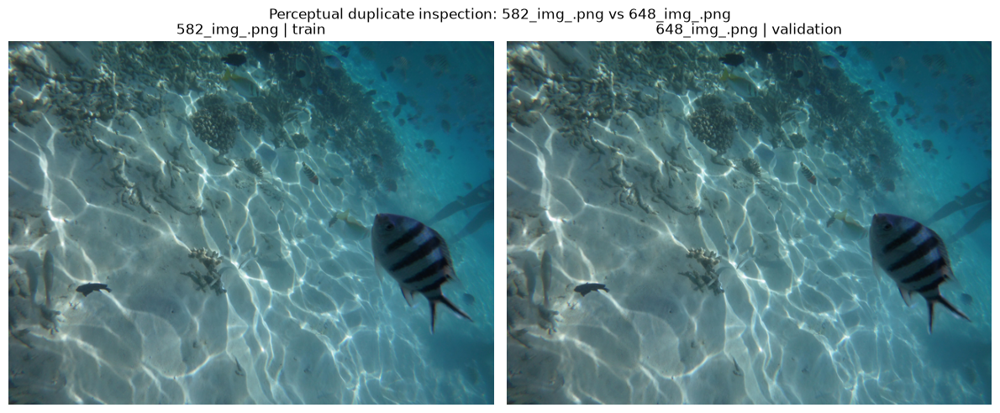

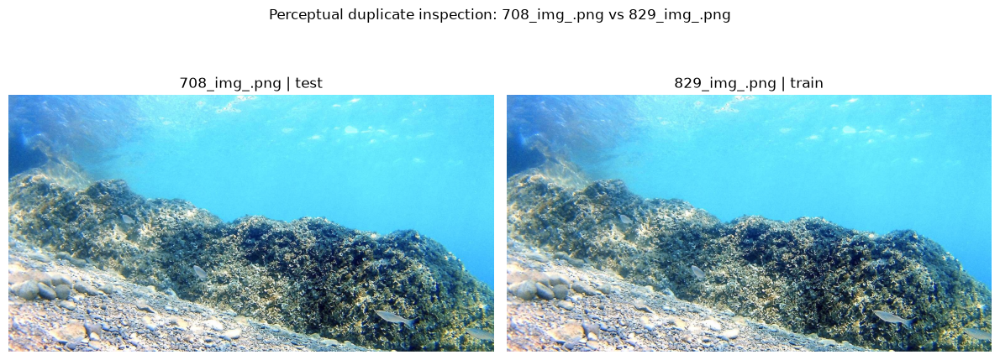

In [112]:
import matplotlib.pyplot as plt
from PIL import Image

pairs_to_inspect = [
    ("582_img_.png", "648_img_.png"),
    ("708_img_.png", "829_img_.png")
]

for img1_name, img2_name in pairs_to_inspect:
    row1 = dataset_manifest[dataset_manifest["filename"] == img1_name].iloc[0]
    row2 = dataset_manifest[dataset_manifest["filename"] == img2_name].iloc[0]

    img1 = Image.open(row1["raw_path"]).convert("RGB")
    img2 = Image.open(row2["raw_path"]).convert("RGB")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(img1)
    axes[0].set_title(f"{img1_name} | {row1['split']}")
    axes[0].axis("off")

    axes[1].imshow(img2)
    axes[1].set_title(f"{img2_name} | {row2['split']}")
    axes[1].axis("off")

    plt.suptitle(f"Perceptual duplicate inspection: {img1_name} vs {img2_name}")
    plt.tight_layout()
    plt.show()

In [113]:
# Create a safe copy and corrected experiment manifest

import os
import pandas as pd

manifest_backup_path = os.path.join(
    PROJECT_ROOT,
    "outputs",
    "day2_degradation_analysis",
    "dataset_manifest_original_backup.csv"
)

corrected_manifest_path = os.path.join(
    PROJECT_ROOT,
    "outputs",
    "day2_degradation_analysis",
    "dataset_manifest_corrected.csv"
)

# Preserve original manifest
dataset_manifest.to_csv(manifest_backup_path, index=False)

# Create a copy for correction
corrected_manifest = dataset_manifest.copy()

# Add exclusion status
corrected_manifest["excluded_duplicate"] = False
corrected_manifest["duplicate_reason"] = ""

duplicate_files_to_exclude = {
    "648_img_.png": "Perceptual duplicate of 582_img_.png",
    "708_img_.png": "Perceptual duplicate of 829_img_.png"
}

for filename, reason in duplicate_files_to_exclude.items():
    mask = corrected_manifest["filename"] == filename
    corrected_manifest.loc[mask, "excluded_duplicate"] = True
    corrected_manifest.loc[mask, "duplicate_reason"] = reason

# Save corrected manifest
corrected_manifest.to_csv(corrected_manifest_path, index=False)

print("Original manifest backup saved.")
print("Corrected manifest saved.")

display(
    corrected_manifest[
        corrected_manifest["excluded_duplicate"]
    ][["filename", "split", "excluded_duplicate", "duplicate_reason"]]
)

Original manifest backup saved.
Corrected manifest saved.


,filename,split,excluded_duplicate,duplicate_reason
590,648_img_.png,validation,True,Perceptual duplicate of 582_img_.png
653,708_img_.png,test,True,Perceptual duplicate of 829_img_.png


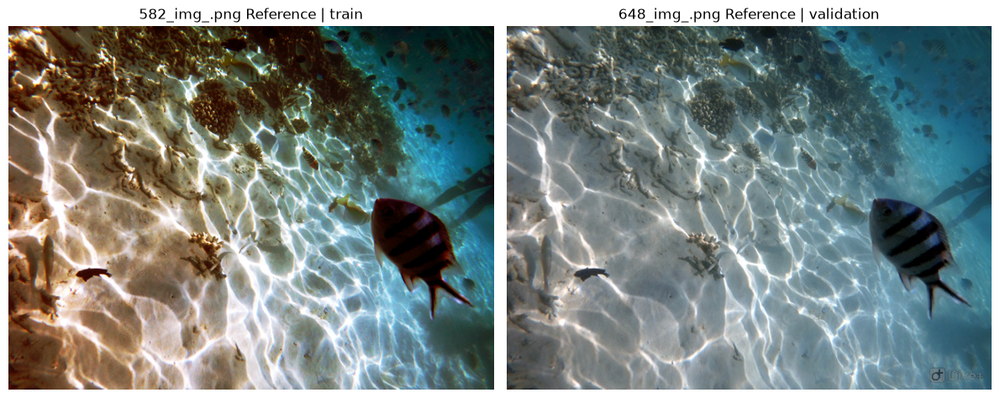

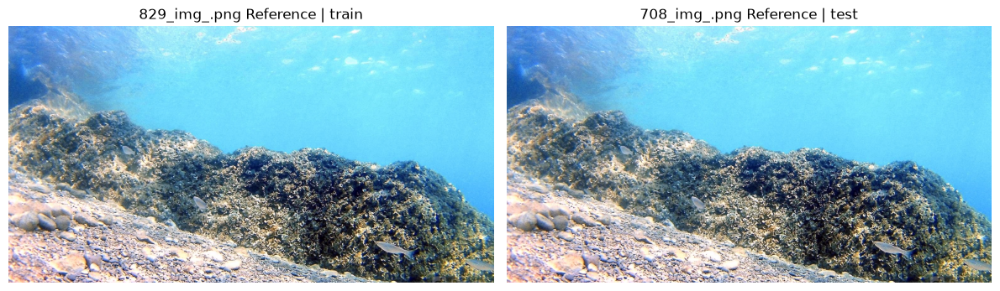

In [114]:
import matplotlib.pyplot as plt
from PIL import Image

pairs_to_check = [
    ("582_img_.png", "648_img_.png"),
    ("829_img_.png", "708_img_.png")
]

for img1_name, img2_name in pairs_to_check:
    row1 = corrected_manifest[corrected_manifest["filename"] == img1_name].iloc[0]
    row2 = corrected_manifest[corrected_manifest["filename"] == img2_name].iloc[0]

    ref1 = Image.open(row1["reference_path"]).convert("RGB")
    ref2 = Image.open(row2["reference_path"]).convert("RGB")

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(ref1)
    axes[0].set_title(f"{img1_name} Reference | {row1['split']}")
    axes[0].axis("off")

    axes[1].imshow(ref2)
    axes[1].set_title(f"{img2_name} Reference | {row2['split']}")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

In [115]:
# Verify the corrected split

usable_manifest = corrected_manifest[
    ~corrected_manifest["excluded_duplicate"]
].copy()

print("Original dataset:", len(dataset_manifest))
print("Excluded duplicates:", corrected_manifest["excluded_duplicate"].sum())
print("Usable dataset:", len(usable_manifest))

print("\nSplit counts after exclusion:")
print(usable_manifest["split"].value_counts())

print("\nExcluded files:")
display(
    corrected_manifest[corrected_manifest["excluded_duplicate"]][
        ["filename", "split", "duplicate_reason"]
    ]
)

Original dataset: 890
Excluded duplicates: 2
Usable dataset: 888

Split counts after exclusion:
split
train         623
test          133
validation    132
Name: count, dtype: int64

Excluded files:


,filename,split,duplicate_reason
590,648_img_.png,validation,Perceptual duplicate of 582_img_.png
653,708_img_.png,test,Perceptual duplicate of 829_img_.png


In [116]:
# Rebuild dataset and DataLoaders using the corrected manifest

usable_manifest = corrected_manifest[
    ~corrected_manifest["excluded_duplicate"]
].copy().reset_index(drop=True)

train_df = usable_manifest[usable_manifest["split"] == "train"].copy()
val_df = usable_manifest[usable_manifest["split"] == "validation"].copy()
test_df = usable_manifest[usable_manifest["split"] == "test"].copy()

print("Corrected dataset counts:")
print(f"Train: {len(train_df)}")
print(f"Validation: {len(val_df)}")
print(f"Test: {len(test_df)}")
print(f"Total: {len(usable_manifest)}")

# Confirm that no excluded image remains
assert not usable_manifest["excluded_duplicate"].any()

# Confirm filenames of excluded images are absent
excluded_filenames = set(
    corrected_manifest.loc[
        corrected_manifest["excluded_duplicate"], "filename"
    ]
)

assert excluded_filenames.isdisjoint(set(usable_manifest["filename"]))

print("\nDataset exclusion verification passed.")

Corrected dataset counts:
Train: 623
Validation: 132
Test: 133
Total: 888

Dataset exclusion verification passed.


In [117]:
import inspect

print("AquaLumeDataset constructor:")
print(inspect.signature(AquaLumeDataset))

print("\nAquaLumeDataset implementation:")
print(inspect.getsource(AquaLumeDataset))

AquaLumeDataset constructor:
(filenames, manifest, raw_dir, ref_dir, scaler)

AquaLumeDataset implementation:


OSError: source code not available

In [118]:
# Inspect existing dataset pipeline variables

candidate_names = [
    "scaler",
    "feature_scaler",
    "degradation_scaler",
    "RAW_DIR",
    "REF_DIR",
    "raw_dir",
    "ref_dir",
    "train_dataset",
    "val_dataset",
    "test_dataset",
    "train_loader",
    "val_loader",
    "test_loader",
    "BATCH_SIZE",
    "batch_size",
    "dataset_manifest",
    "corrected_manifest",
    "usable_manifest"
]

for name in candidate_names:
    if name in globals():
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")
        if isinstance(obj, (str, int, float)):
            print(f"    Value: {obj}")

scaler: StandardScaler
RAW_DIR: WindowsPath
REF_DIR: WindowsPath
train_dataset: AquaLumeDataset
val_dataset: AquaLumeDataset
test_dataset: AquaLumeDataset
train_loader: DataLoader
val_loader: DataLoader
test_loader: DataLoader
BATCH_SIZE: int
    Value: 8
batch_size: int
    Value: 8
dataset_manifest: DataFrame
corrected_manifest: DataFrame
usable_manifest: DataFrame


In [119]:
print("Existing train_dataset attributes:")
print(train_dataset.__dict__.keys())

print("\nExisting train_dataset stored values:")
for key, value in train_dataset.__dict__.items():
    print(f"{key}: {type(value).__name__}")

Existing train_dataset attributes:
dict_keys(['filenames', 'manifest', 'raw_dir', 'ref_dir', 'scaler', 'feature_columns'])

Existing train_dataset stored values:
filenames: list
manifest: DataFrame
raw_dir: WindowsPath
ref_dir: WindowsPath
scaler: StandardScaler
feature_columns: list


In [120]:
from torch.utils.data import DataLoader

# Filenames for each corrected split
train_filenames = train_df["filename"].tolist()
val_filenames = val_df["filename"].tolist()
test_filenames = test_df["filename"].tolist()

# Rebuild datasets using the corrected manifest
train_dataset = AquaLumeDataset(
    train_filenames, usable_manifest, RAW_DIR, REF_DIR, scaler
)

val_dataset = AquaLumeDataset(
    val_filenames, usable_manifest, RAW_DIR, REF_DIR, scaler
)

test_dataset = AquaLumeDataset(
    test_filenames, usable_manifest, RAW_DIR, REF_DIR, scaler
)

# Rebuild DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

print("Corrected DataLoaders rebuilt successfully.")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Corrected DataLoaders rebuilt successfully.
Train batches: 78
Validation batches: 17
Test batches: 17


In [121]:
# Verify one batch from each corrected DataLoader

for loader_name, loader in [
    ("Train", train_loader),
    ("Validation", val_loader),
    ("Test", test_loader)
]:
    batch = next(iter(loader))

    images, targets, degradation_features, filenames = batch

    print(f"\n{loader_name} loader:")
    print("Input shape:", images.shape)
    print("Target shape:", targets.shape)
    print("Degradation features shape:", degradation_features.shape)
    print("Input range:", images.min().item(), "to", images.max().item())
    print("Target range:", targets.min().item(), "to", targets.max().item())
    print("Sample filenames:", filenames[:3])


Train loader:


AttributeError: 'str' object has no attribute 'shape'

In [122]:
batch = next(iter(train_loader))

print("Batch type:", type(batch))
print("Number of batch elements:", len(batch))

for i, item in enumerate(batch):
    print(f"\nElement {i}:")
    print("Type:", type(item))

    if hasattr(item, "shape"):
        print("Shape:", item.shape)
    else:
        print("Sample:", item[:3] if isinstance(item, (list, tuple)) else item)

Batch type: <class 'dict'>
Number of batch elements: 4

Element 0:
Type: <class 'str'>
Sample: input

Element 1:
Type: <class 'str'>
Sample: target

Element 2:
Type: <class 'str'>
Sample: degradation

Element 3:
Type: <class 'str'>
Sample: filename


In [123]:
# Verify corrected DataLoaders

for loader_name, loader in [
    ("Train", train_loader),
    ("Validation", val_loader),
    ("Test", test_loader)
]:
    batch = next(iter(loader))

    images = batch["input"]
    targets = batch["target"]
    degradation_features = batch["degradation"]
    filenames = batch["filename"]

    print(f"\n{loader_name} loader:")
    print("Input shape:", images.shape)
    print("Target shape:", targets.shape)
    print("Degradation features shape:", degradation_features.shape)
    print("Input range:", images.min().item(), "to", images.max().item())
    print("Target range:", targets.min().item(), "to", targets.max().item())
    print("Sample filenames:", filenames[:3])


Train loader:
Input shape: torch.Size([8, 3, 256, 256])
Target shape: torch.Size([8, 3, 256, 256])
Degradation features shape: torch.Size([8, 3])
Input range: 0.0 to 1.0
Target range: 0.0 to 1.0
Sample filenames: ['799_img_.png', '2_img_.png', '530_img_.png']

Validation loader:
Input shape: torch.Size([8, 3, 256, 256])
Target shape: torch.Size([8, 3, 256, 256])
Degradation features shape: torch.Size([8, 3])
Input range: 0.0 to 1.0
Target range: 0.0 to 1.0
Sample filenames: ['10151.png', '104_img_.png', '106_img_.png']

Test loader:
Input shape: torch.Size([8, 3, 256, 256])
Target shape: torch.Size([8, 3, 256, 256])
Degradation features shape: torch.Size([8, 3])
Input range: 0.0 to 1.0
Target range: 0.0 to 1.0
Sample filenames: ['10909.png', '116_img_.png', '118_img_.png']


In [124]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("No GPU available in this environment.")

PyTorch version: 2.15.0+cpu
CUDA available: False
No GPU available in this environment.


In [125]:
import inspect

print("===== TRAIN FUNCTION =====")
try:
    print(inspect.getsource(train_one_epoch))
except OSError:
    print("Source unavailable for train_one_epoch")

print("\n===== VALIDATION FUNCTION =====")
try:
    print(inspect.getsource(validate_one_epoch))
except OSError:
    print("Source unavailable for validate_one_epoch")

===== TRAIN FUNCTION =====
def train_one_epoch(model, loader, optimizer, device):

    model.train()

    running_losses = {
        "total": 0.0,
        "l1": 0.0,
        "ssim": 0.0,
        "gradient": 0.0
    }

    num_batches = len(loader)

    for batch_data in loader:

        inputs = batch_data["input"].to(device)
        targets = batch_data["target"].to(device)
        degradation = batch_data["degradation"].to(device)

        optimizer.zero_grad(set_to_none=True)

        predictions, branch_weights = model(inputs, degradation)

        total_loss, l1, ssim_loss, grad_loss = aqualume_loss(
            predictions, targets
        )

        total_loss.backward()

        optimizer.step()

        running_losses["total"] += total_loss.item()
        running_losses["l1"] += l1.item()
        running_losses["ssim"] += ssim_loss.item()
        running_losses["gradient"] += grad_loss.item()

    epoch_losses = {
        key: value / num_batches
        for key, value in runn

In [126]:
def train_one_epoch(model, loader, optimizer, device):

    model.train()

    running_losses = {
        "total": 0.0,
        "l1": 0.0,
        "ssim": 0.0,
        "gradient": 0.0
    }

    total_samples = 0

    for batch_data in loader:

        inputs = batch_data["input"].to(device)
        targets = batch_data["target"].to(device)
        degradation = batch_data["degradation"].to(device)

        batch_size = inputs.size(0)

        optimizer.zero_grad(set_to_none=True)

        predictions, branch_weights = model(inputs, degradation)

        total_loss, l1, ssim_loss, grad_loss = aqualume_loss(
            predictions, targets
        )

        total_loss.backward()
        optimizer.step()

        running_losses["total"] += total_loss.item() * batch_size
        running_losses["l1"] += l1.item() * batch_size
        running_losses["ssim"] += ssim_loss.item() * batch_size
        running_losses["gradient"] += grad_loss.item() * batch_size

        total_samples += batch_size

    epoch_losses = {
        key: value / total_samples
        for key, value in running_losses.items()
    }

    return epoch_losses


def validate_one_epoch(model, loader, device):

    model.eval()

    running_losses = {
        "total": 0.0,
        "l1": 0.0,
        "ssim": 0.0,
        "gradient": 0.0
    }

    total_samples = 0

    with torch.no_grad():

        for batch_data in loader:

            inputs = batch_data["input"].to(device)
            targets = batch_data["target"].to(device)
            degradation = batch_data["degradation"].to(device)

            batch_size = inputs.size(0)

            predictions, branch_weights = model(
                inputs, degradation
            )

            total_loss, l1, ssim_loss, grad_loss = aqualume_loss(
                predictions, targets
            )

            running_losses["total"] += total_loss.item() * batch_size
            running_losses["l1"] += l1.item() * batch_size
            running_losses["ssim"] += ssim_loss.item() * batch_size
            running_losses["gradient"] += grad_loss.item() * batch_size

            total_samples += batch_size

    epoch_losses = {
        key: value / total_samples
        for key, value in running_losses.items()
    }

    return epoch_losses

In [128]:
from pathlib import Path

checkpoint_dir = Path(CHECKPOINT_DIR)
best_model_path = Path(BEST_MODEL_PATH)

print("Checkpoint directory:", checkpoint_dir)
print("Checkpoint directory exists:", checkpoint_dir.exists())

print("\nCheckpoint files:")
if checkpoint_dir.exists():
    for file in checkpoint_dir.iterdir():
        print("-", file.name)

print("\nBest model checkpoint path:", best_model_path)
print("Best model path parent exists:", best_model_path.parent.exists())

Checkpoint directory: outputs\checkpoints
Checkpoint directory exists: True

Checkpoint files:

Best model checkpoint path: outputs\checkpoints\aqualume_best_model.pth
Best model path parent exists: True


In [129]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seeds set to:", SEED)

Random seeds set to: 42


In [130]:
import json
from pathlib import Path

EXPERIMENT_CONFIG = {
    "project": "AquaLume",
    "research_question": (
        "Can degradation-aware fusion of CNN, ViT and physics-inspired "
        "features improve underwater image enhancement?"
    ),
    "dataset": "UIEB",
    "seed": SEED,
    "image_size": 256,
    "batch_size": BATCH_SIZE,
    "train_samples": len(train_dataset),
    "validation_samples": len(val_dataset),
    "test_samples": len(test_dataset),
    "model_parameters": 514118,
    "optimizer": "Adam",
    "learning_rate": 0.0001,
    "weight_decay": 0.00001,
    "max_epochs": 50,
    "early_stopping_patience": 8,
    "scheduler": "ReduceLROnPlateau",
    "loss": {
        "l1_weight": 1.0,
        "ssim_weight": 0.5,
        "gradient_weight": 0.1
    },
    "device_at_preparation": str(DEVICE)
}

CONFIG_DIR = Path("outputs/experiment")
CONFIG_DIR.mkdir(parents=True, exist_ok=True)

CONFIG_PATH = CONFIG_DIR / "aqualume_experiment_config.json"

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(EXPERIMENT_CONFIG, f, indent=4)

print("Experiment configuration saved:", CONFIG_PATH)

Experiment configuration saved: outputs\experiment\aqualume_experiment_config.json
